# 05 · Advanced Cricket Analytics (Phase 5)

Goes beyond Phase 3 EDA: score distributions and consistency with confidence intervals, **season- and
phase-adjusted** player and team metrics, **chase-state** analysis (runs needed, balls left, wickets in hand at
the end of each over), pressure and close-match analysis, venue tests, and an **assessed** predictive task.

All logic lives in `python/05_advanced_analytics.py`; this notebook executes it and walks through every finding
in the required format: question, metric definition, calculation, sample size, result, interpretation, limitations.

**Rules applied throughout:** regulation balls only (super overs excluded); bowler-credited wickets only;
retired hurt is not out; batting order and outcome from `batting_first_team` / `chasing_team` / `result_for`;
D/L and shortened matches excluded from target-based comparisons; 7-legal-ball overs retained.

> MySQL cross-checks (M01-M04) need `MYSQL_USER` / `MYSQL_PASSWORD` in the environment. If they are missing,
> those checks are reported as FAIL, never skipped silently.

In [1]:
import os, sys
from pathlib import Path
from importlib import import_module
import pandas as pd
from IPython.display import Image, Markdown, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / 'python'))
for k in ('MYSQL_USER', 'MYSQL_PASSWORD'):          # read from the Windows user environment if not inherited
    if not os.environ.get(k) and os.name == 'nt':
        import winreg
        try:
            with winreg.OpenKey(winreg.HKEY_CURRENT_USER, 'Environment') as key:
                os.environ[k] = winreg.QueryValueEx(key, k)[0]
        except OSError:
            pass
adv = import_module('05_advanced_analytics')
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 100)

A, F, val = adv.build_all()
FD = {f.qid: f for f in F}
print(f'{len(F)} findings | chase base: {len(A.chase_matches)} matches | chase states: {len(A.states):,} | '
      f'validation: {(val.status == "PASS").sum()}/{len(val)} PASS')
print('Thresholds:', adv.TH)

def show(qid):
    f = FD[qid]
    display(Markdown(f"**1. Question.** {f.question}\n\n**2. Metric.** {f.definition}\n\n"
                     f"**3. Calculation.** `{f.calc_ref}`\n\n**4. Sample.** {f.sample}"))
    display(f.table.head(15))
    for name, t in f.extra.items():
        display(Markdown(f'**{name}**')); display(t.head(12))
    if f.chart:
        display(Image(filename=str(PROJECT_ROOT / 'reports' / f.chart), width=900))
    display(Markdown(f"**6. Interpretation.** {f.insight}\n\n**7. Limitations.** {f.limitation}"))

32 findings | chase base: 1047 matches | chase states: 18,817 | validation: 30/30 PASS
Thresholds: {'bat_innings': 50, 'bat_balls': 500, 'death_balls': 250, 'non_death_balls': 500, 'season_balls': 100, 'season_min_seasons': 6, 'split_innings': 30, 'bowl_balls': 1000, 'phase_bowl_balls': 600, 'bowl_season_balls': 120, 'bowl_min_seasons': 6, 'close_bat_balls': 150, 'close_matches_team': 20, 'venue_matches': 20}


## Validation first

In [2]:
val[['check_id', 'area', 'check', 'expected', 'actual', 'status']]

,check_id,area,check,expected,actual,status
0,P01,Totals vs Phase 3,Regulation deliveries / runs,"260,759 / 347,470","260,759 / 347,470",PASS
1,P02,Totals vs Phase 3,Season runs table sums to total,347470,347470,PASS
2,P03,Legal balls & wickets,Phase legal balls / bowler wickets sum to totals,"251,319 / 11,795","251,319 / 11,795",PASS
3,P04,Aggregation,Team x phase batting runs sum to regulation runs,347470,347470,PASS
4,P05,Aggregation,Team x phase bowling wickets sum to bowler wickets,11795,11795,PASS
5,P06,Aggregation,Bowler-adjusted table: wickets / balls equal Phase 3 bowler careers,11795 / 251319,11795 / 251319,PASS
6,P07,Aggregation,Expected runs (season x phase) sum to actual league runs (adjustment is unbiased),347470,347470.0,PASS
7,P08,Aggregation,Expected bowler wickets sum to actual,11795,11795.0,PASS
8,P09,Phase,"Phase assignment: PP 1-6, Middle 7-15, Death 16-20, no super-over phase",0 violations,0,PASS
9,P10,Super overs,No super-over deliveries in any Phase 5 base table,0,0,PASS


## A. Batting

### A1

In [3]:
show('A1')

**1. Question.** Which batters most reliably make a meaningful contribution, and how certain are we of the ranking?

**2. Metric.** pct_30_plus = innings with >= 30 runs / innings; 95% Wilson score interval; IQR of innings scores.

**3. Calculation.** `a1_consistency`

**4. Sample.** Batters with >= 50 innings (n = 103).

,player,innings,mean,median,iqr,pct_30_plus,ci_low,ci_high
476,RD Gaikwad,65,36.6,32.0,54.0,55.4,43.3,66.8
545,SE Marsh,69,35.9,32.0,48.0,53.6,42.0,64.9
150,DA Warner,184,35.7,33.0,49.0,52.2,45.0,59.3
292,KL Rahul,123,38.1,29.0,45.5,48.8,40.1,57.5
355,MEK Hussey,58,34.1,24.0,47.5,48.3,35.9,60.8
191,F du Plessis,138,33.1,29.0,40.0,47.8,39.7,56.1
566,SR Tendulkar,78,29.9,27.5,32.0,47.4,36.7,58.4
635,V Kohli,244,32.8,25.0,40.0,47.1,41.0,53.4
595,Shubman Gill,100,32.2,27.0,39.5,47.0,37.5,56.7
493,RR Pant,110,29.9,27.0,34.0,45.5,36.5,54.8


**6. Interpretation.** RD Gaikwad reaches 30 in 55.4% of 65 innings (95% CI 43.3-66.8%). The intervals are wide: 10 of the top 10 have a lower bound at or below the 10th-ranked player's rate (45.5%), so the order within the top 10 is not statistically settled. However, 10 of the top 10 have a lower bound above the median qualifying batter's rate (31.5%), so they are reliably more consistent than a typical batter.

**7. Limitations.** Batting position is not in the data; openers get more opportunity to reach 30 than finishers.

### A2

In [4]:
show('A2')

**1. Question.** How often do batters reach milestone scores, and who converts fifties into hundreds?

**2. Metric.** Share of innings reaching 30 / 50 / 100; conversion = hundreds / innings of 50+.

**3. Calculation.** `a2_milestones`

**4. Sample.** League: 16,842 batting innings. Ranking: batters with >= 50 innings (n = 103).

,player,innings,pct_30_plus,pct_50_plus,pct_100_plus,fifties_plus,hundreds,conversion_50_to_100_pct
17,DA Warner,184,52.2,35.9,2.2,66,4,6.1
41,KL Rahul,123,48.8,33.3,3.3,41,4,9.8
70,RD Gaikwad,65,55.4,30.8,3.1,20,2,10.0
80,SE Marsh,69,53.6,30.4,1.4,21,1,4.8
49,MEK Hussey,58,48.3,27.6,1.7,16,1,6.2
24,F du Plessis,138,47.8,26.8,0.0,37,0,0.0
13,CH Gayle,141,43.3,26.2,4.3,37,6,16.2
95,V Kohli,244,47.1,25.8,3.3,63,8,12.7
1,AB de Villiers,170,38.8,25.3,1.8,43,3,7.0
32,JC Buttler,106,38.7,24.5,6.6,26,7,26.9


**6. Interpretation.** League-wide, 24.4% of innings reach 30, 10.6% reach 50 and 0.60% reach 100. DA Warner reaches 50 most often (35.9% of innings). Among batters with 20+ scores of 50 or more, JC Buttler converts best (7 hundreds from 26 innings of 50+, 26.9%).

**7. Limitations.** Not-out innings are included as scored (a 45* counts as 'not 50').

### A3

**1. Question.** What does a typical innings look like, versus the average?

**2. Metric.** Quartiles, mean and skewness of per-innings runs.

**3. Calculation.** `a3_distribution`

**4. Sample.** 12 leading run scorers (2,366 innings); skewness for all 103 batters with >= 50 innings.

,player,count,mean,25%,50%,75%,max,skew
0,V Kohli,244.0,32.8,10.0,25.0,50.0,113.0,0.9
1,S Dhawan,221.0,30.6,9.0,25.0,46.0,106.0,0.9
2,RG Sharma,252.0,26.3,6.0,19.0,41.2,109.0,1.0
3,DA Warner,184.0,35.7,8.0,33.0,57.0,126.0,0.6
4,SK Raina,200.0,27.6,8.0,23.0,41.5,100.0,1.0
5,MS Dhoni,229.0,22.9,8.0,21.0,31.0,84.0,0.9
6,AB de Villiers,170.0,30.4,8.2,21.5,49.5,133.0,1.1
7,CH Gayle,141.0,35.2,9.0,23.0,51.0,175.0,1.2
8,RV Uthappa,197.0,25.1,8.0,22.0,36.0,88.0,0.9
9,KD Karthik,234.0,20.7,6.0,17.0,30.0,97.0,1.2


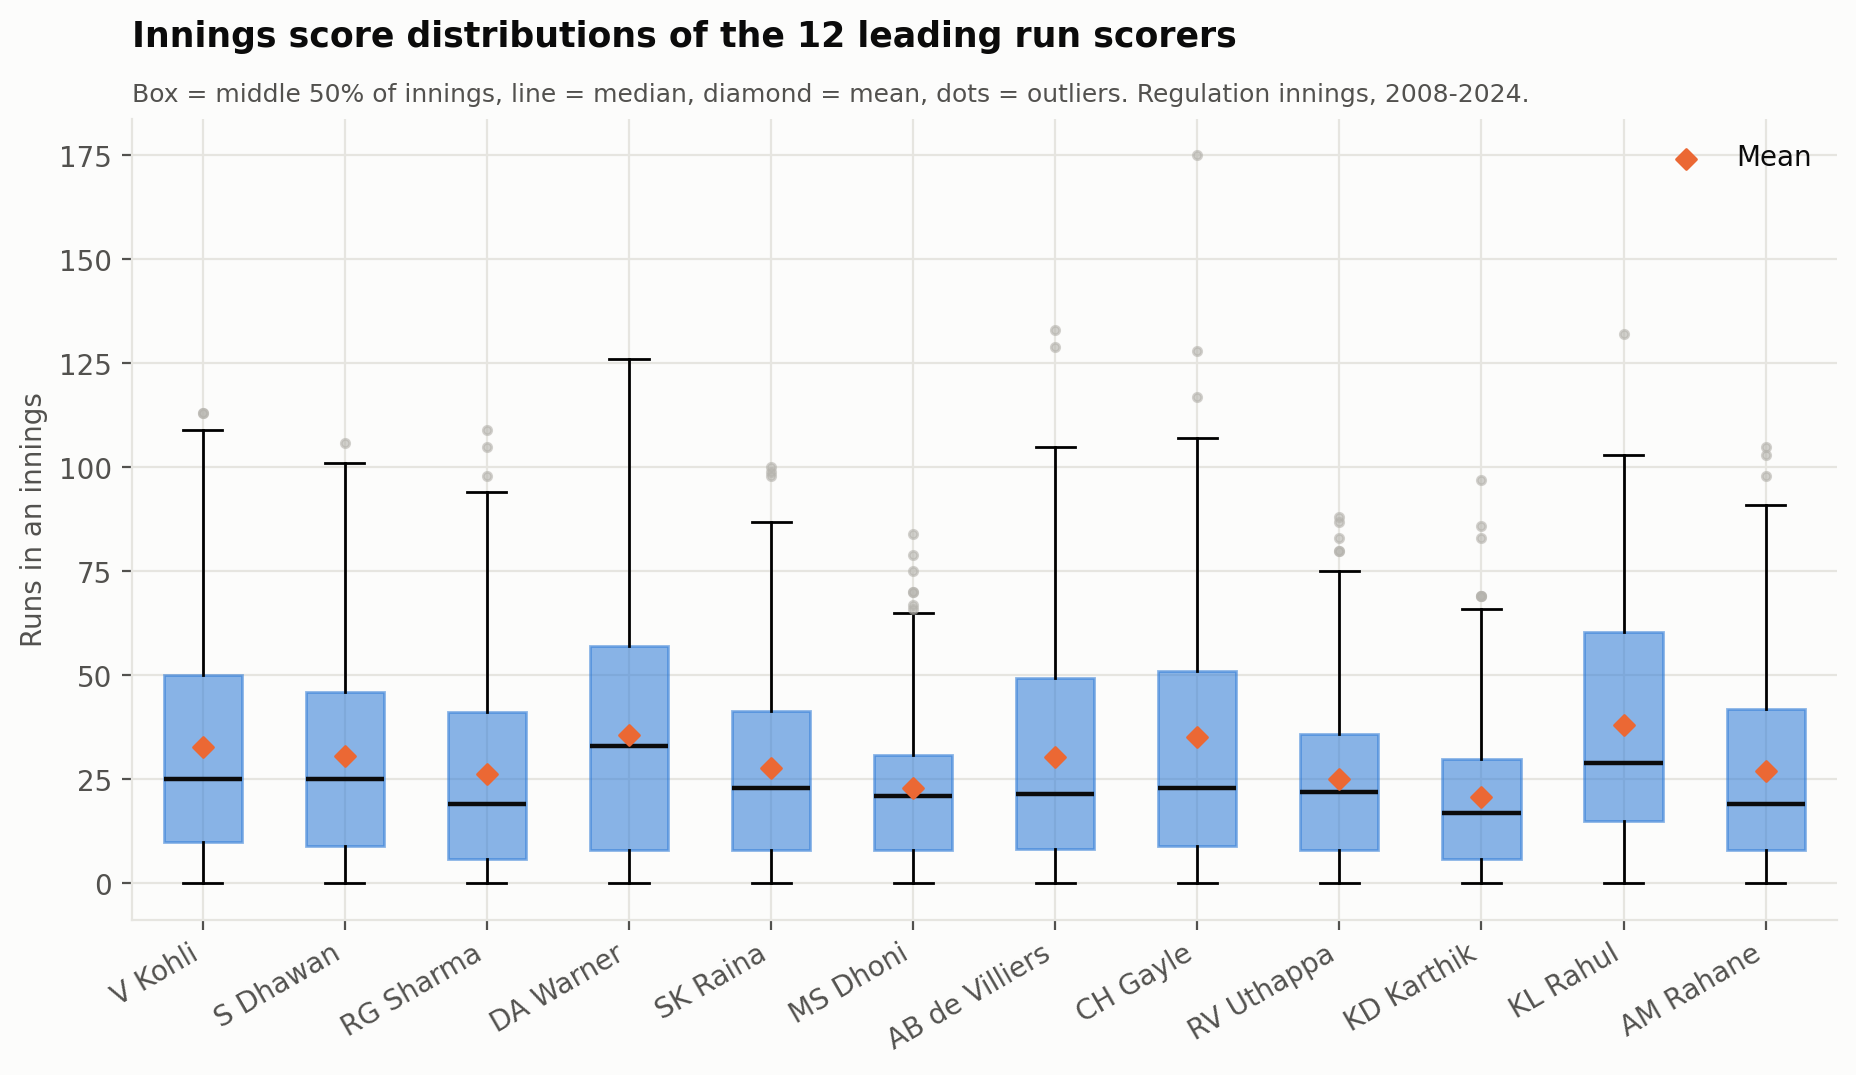

**6. Interpretation.** Every qualifying batter's score distribution is right-skewed (skewness > 0 for 103 of 103); the median innings is below the mean for all 12 leaders (12/12). Example: V Kohli's median innings is 25 vs a mean of 32.8. Averages therefore overstate a 'typical' innings; medians and milestone rates (A1-A2) describe reliability better.

**7. Limitations.** Distributions mix batting positions and eras.

In [5]:
show('A3')

### A4

**1. Question.** Do batters score by hitting boundaries, by avoiding dot balls, or both?

**2. Metric.** boundary % = (4s + 6s) / balls faced; dot % = balls faced with 0 batter runs / balls faced (batter view, so leg-byes off a 'dot' still count as a batter dot); Spearman rank correlation.

**3. Calculation.** `a4_boundary_dot`

**4. Sample.** Batters with >= 500 balls faced (n = 123).

,player,balls,strike_rate,boundary_pct,dot_pct,boundary_run_share
100,SP Narine,925,165.8,28.2,44.4,80.7
4,AD Russell,1420,174.9,26.7,38.8,77.9
115,V Sehwag,1755,155.4,25.1,37.5,72.3
120,YBK Jaiswal,1067,150.6,24.6,40.4,73.4
77,PP Shaw,1283,147.5,23.3,37.7,69.7
106,ST Jayasuriya,532,144.4,23.1,47.2,74.2
74,P Simran Singh,517,146.2,23.0,44.5,73.8
17,CH Gayle,3333,149.0,22.9,44.0,75.8
56,LS Livingstone,578,162.5,22.8,33.6,70.3
11,Abhishek Sharma,887,155.2,22.7,35.9,69.0


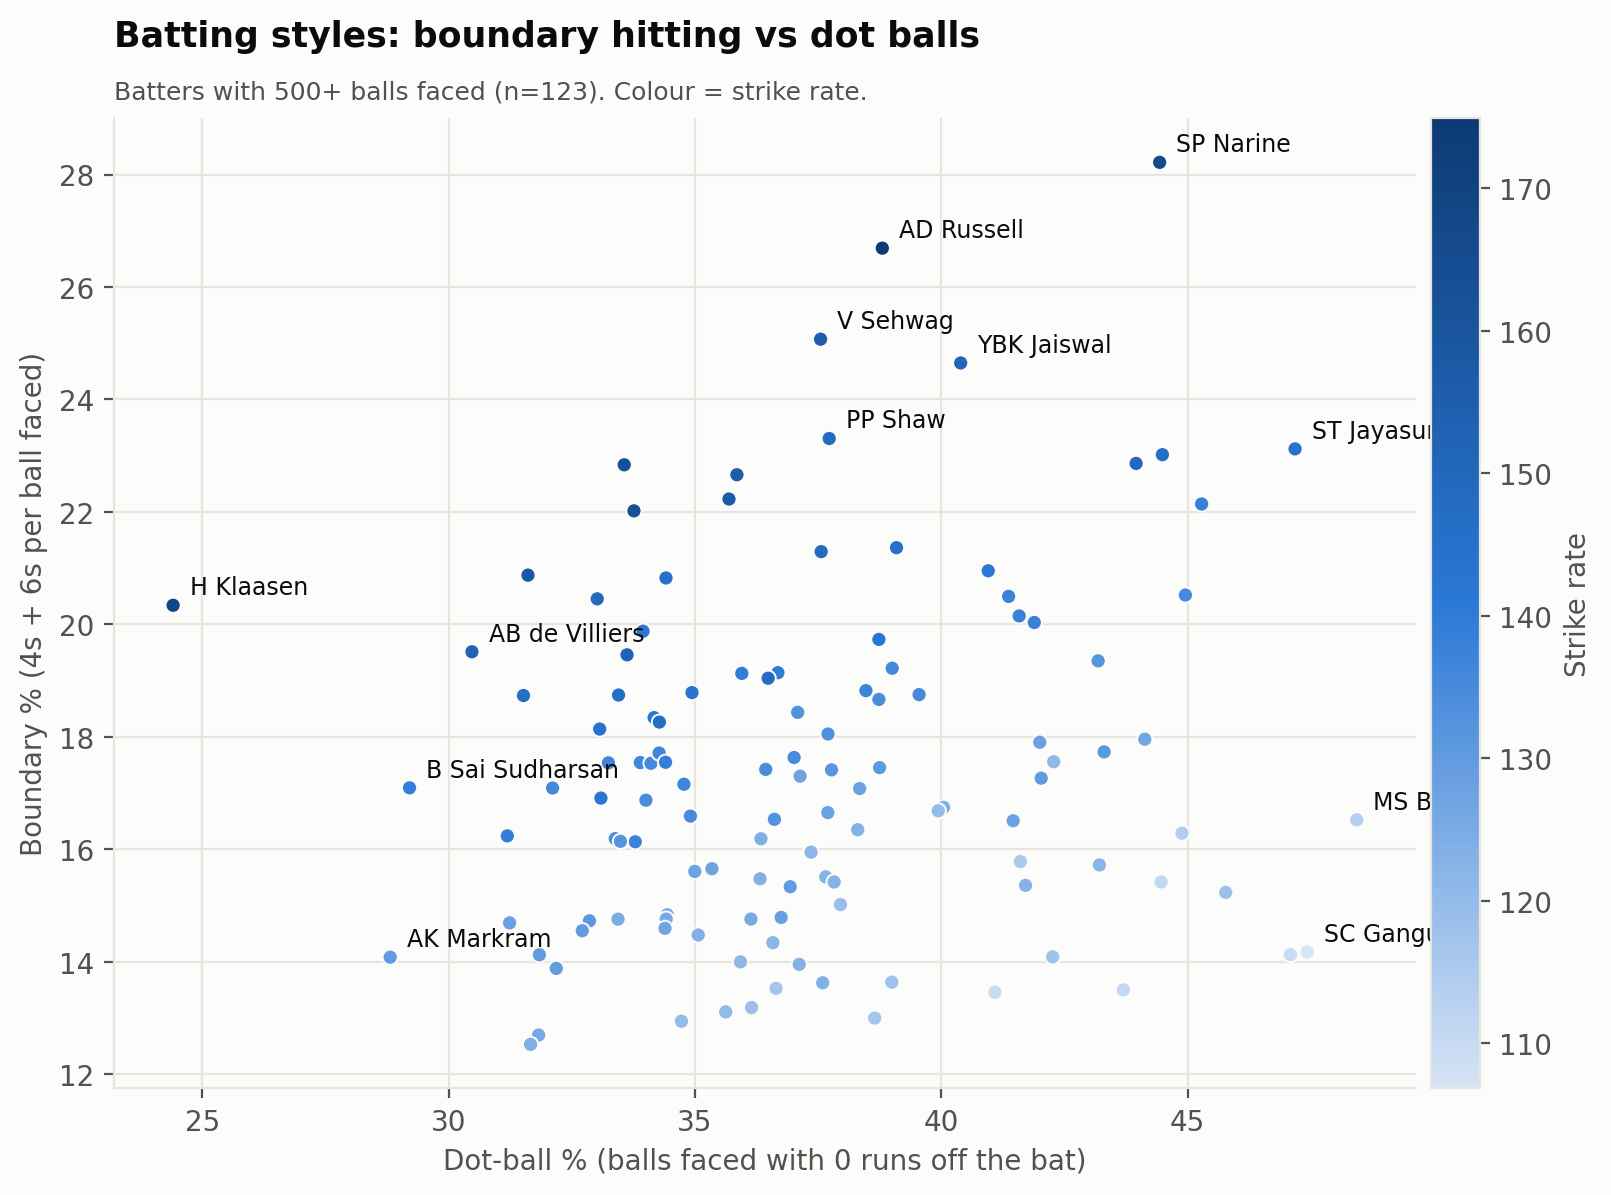

**6. Interpretation.** SP Narine hits a boundary off 28.2% of balls. Across batters, the relationship between boundary % and dot % is weak and not statistically significant (rho = 0.13, p = 0.137) - both styles (boundary-heavy with many dots, and low-dot rotation) exist side by side. Strike rate tracks boundary % (rho = 0.84) more closely than low dot % (rho = -0.32).

**7. Limitations.** Proxy fours/sixes (batsman_runs = 4/6). No shot or field data.

In [6]:
show('A4')

### A5

**1. Question.** Which batters lift their scoring rate most in overs 16-20?

**2. Metric.** acceleration = strike rate in death overs - strike rate in overs 1-15 (same batter).

**3. Calculation.** `a5_death_acceleration`

**4. Sample.** Batters with >= 250 death balls and >= 500 balls in overs 1-15 (n = 51).

,player,balls_pre,sr_pre,balls_death,sr_death,acceleration
0,AB de Villiers,2565.0,128.4,838.0,222.9,94.5
9,DJ Bravo,682.0,95.5,522.0,174.1,78.7
27,MS Dhoni,1946.0,100.3,1866.0,176.4,76.2
34,RR Pant,1751.0,134.8,454.0,203.3,68.5
50,Yuvraj Singh,1619.0,113.9,501.0,180.8,66.9
17,JP Duminy,1116.0,102.8,520.0,169.6,66.8
45,V Kohli,5281.0,123.7,784.0,187.4,63.6
6,CH Gayle,3049.0,143.8,284.0,204.6,60.8
33,RG Sharma,4218.0,121.3,836.0,181.0,59.7
44,SV Samson,2770.0,131.4,410.0,190.2,58.9


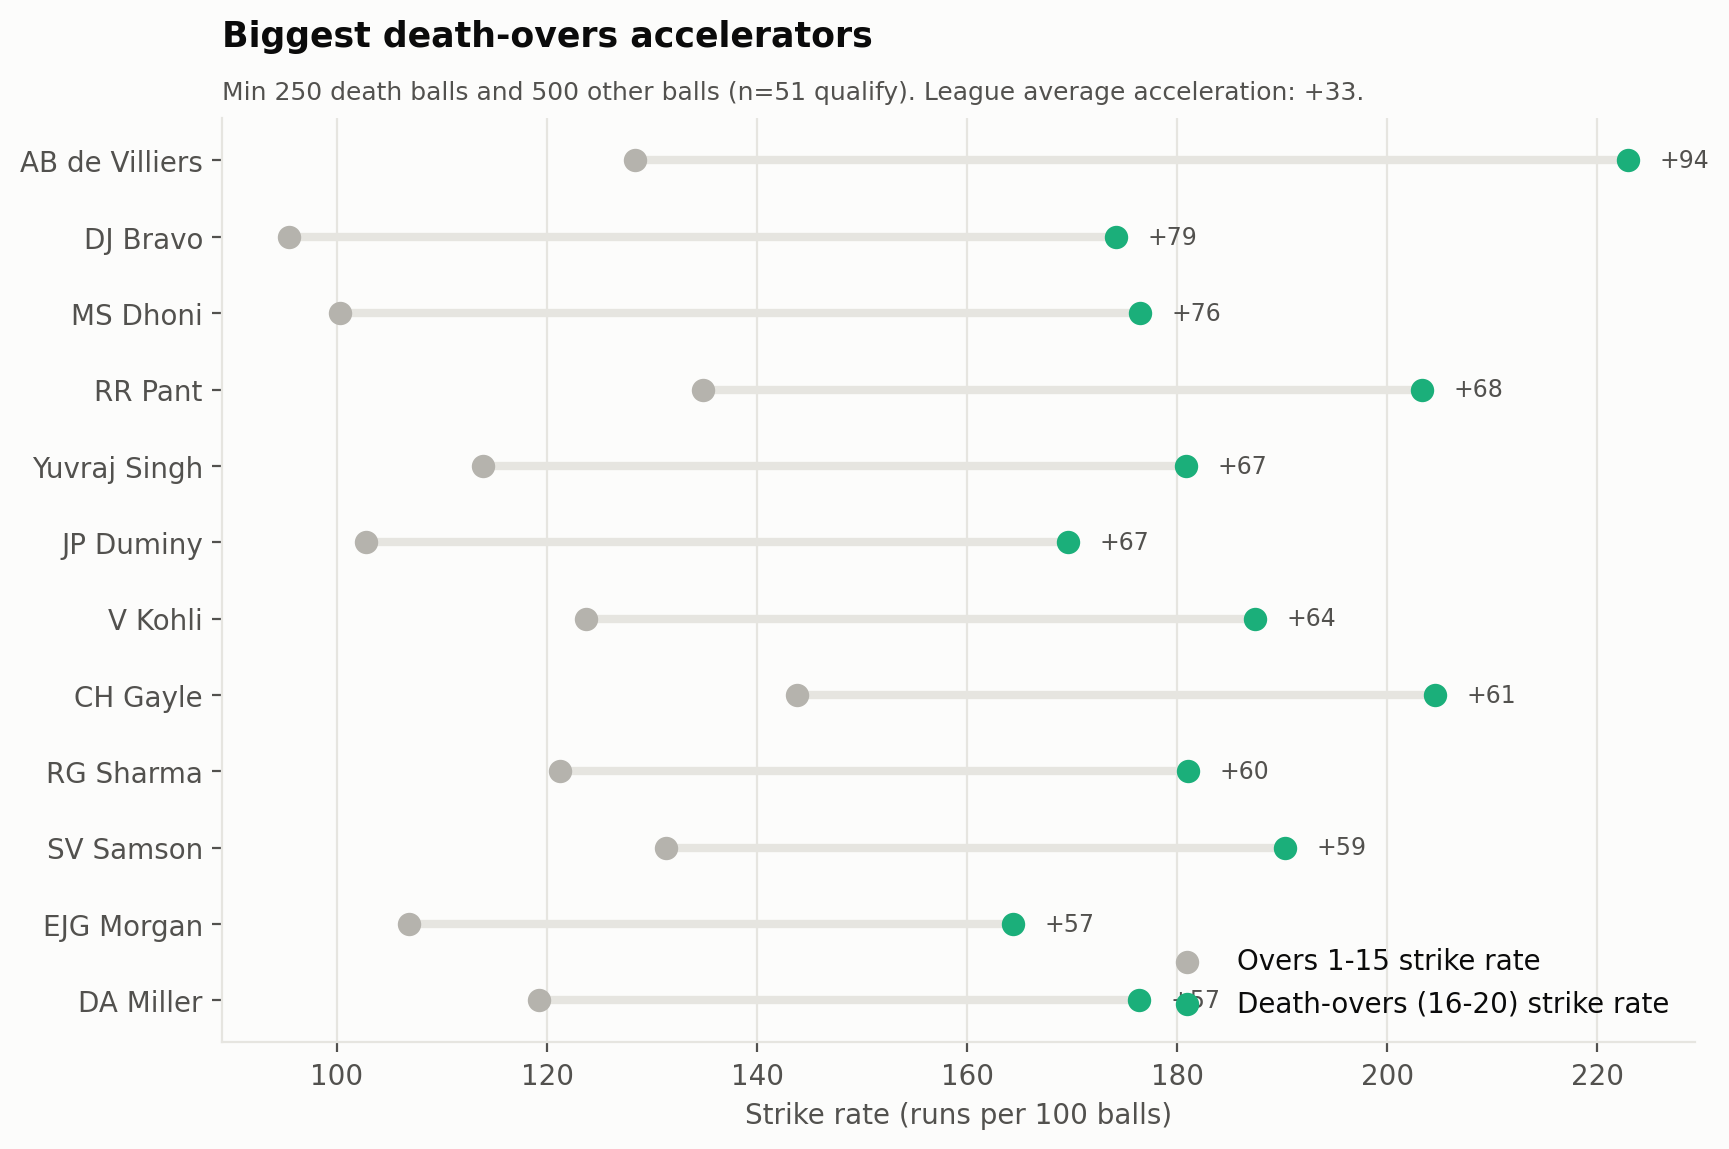

**6. Interpretation.** League-wide, strike rate rises by 32.6 in the death overs. AB de Villiers accelerates most (+94.5: 128.4 -> 222.9), followed by DJ Bravo (+78.7). 51 of 51 qualifying batters score faster at the death; the smallest change is N Pooran (+11.9).

**7. Limitations.** Selection effect: batters who reach the death overs are often set; finishers who only bat late face fewer pre-death balls.

In [7]:
show('A5')

### A6

In [8]:
show('A6')

**1. Question.** Whose scoring rate is steady from season to season, and whose swings widely?

**2. Metric.** Per qualifying season: strike rate minus the league strike rate that season (removes the 2023-24 scoring jump); variability = standard deviation of that difference across seasons.

**3. Calculation.** `a6_season_variability`

**4. Sample.** Seasons with >= 100 balls faced; batters with >= 6 such seasons (n = 62).

,group,player,seasons,mean_sr_vs_league,sd_sr_vs_league,min_sr,max_sr
21,most stable,JP Duminy,7,-1.6,5.4,114.5,134.4
40,most stable,R Dravid,6,-6.1,5.8,109.2,128.6
20,most stable,JH Kallis,7,-14.5,6.3,96.6,117.1
32,most stable,MP Stoinis,6,6.8,7.5,135.2,150.0
35,most stable,N Rana,7,1.4,8.4,122.0,146.4
43,most stable,RG Sharma,17,0.5,8.6,114.9,150.0
54,most stable,SS Iyer,8,-6.6,9.3,102.3,146.9
13,most stable,F du Plessis,11,0.9,9.4,123.4,161.6
16,most variable,HH Pandya,8,11.8,27.5,113.4,191.4
25,most variable,KH Pandya,8,-1.6,27.4,113.9,191.1


**6. Interpretation.** The steadiest batter is JP Duminy (season-adjusted strike rate varies by SD 5.4 over 7 seasons); the most variable is HH Pandya (SD 27.5, from 113 to 191). The median SD across qualifying batters is 15.1 strike-rate points. Much of this is sampling noise: with a per-ball run SD of 1.65, a season's strike rate has a standard error of about 16 points at 100 balls and 10 at 250 balls.

**7. Limitations.** Role changes (opener vs finisher) across seasons are not visible in the data.

### A7

**1. Question.** Do batters perform differently when setting a target versus chasing one?

**2. Metric.** Per batter: strike rate and runs per innings in innings 1 vs innings 2; Wilcoxon signed-rank test (paired, non-parametric) across batters.

**3. Calculation.** `a7_first_vs_chasing`

**4. Sample.** Batters with >= 30 innings in both roles (n = 74).

,player,innings_1,sr_bat_first,innings_2,sr_chasing,sr_diff,rpi_bat_first,rpi_chasing
16,DR Smith,47.0,123.1,42.0,147.8,24.8,23.5,30.5
1,AC Gilchrist,41.0,127.4,39.0,149.1,21.7,23.0,28.9
72,YK Pathan,73.0,132.0,81.0,151.9,19.9,18.2,23.2
42,N Pooran,35.0,152.6,38.0,170.6,18.1,22.0,26.3
70,V Sehwag,49.0,147.8,55.0,163.1,15.2,26.6,25.9
25,JC Buttler,49.0,140.6,57.0,155.0,14.4,36.3,31.6
33,KM Jadhav,41.0,136.3,40.0,111.8,-24.5,15.1,14.7
0,AB de Villiers,88.0,162.0,82.0,137.9,-24.1,35.9,24.4
22,Harbhajan Singh,44.0,149.5,46.0,126.6,-22.9,10.2,8.4
65,SS Tiwary,39.0,130.1,34.0,108.6,-21.5,22.2,18.5


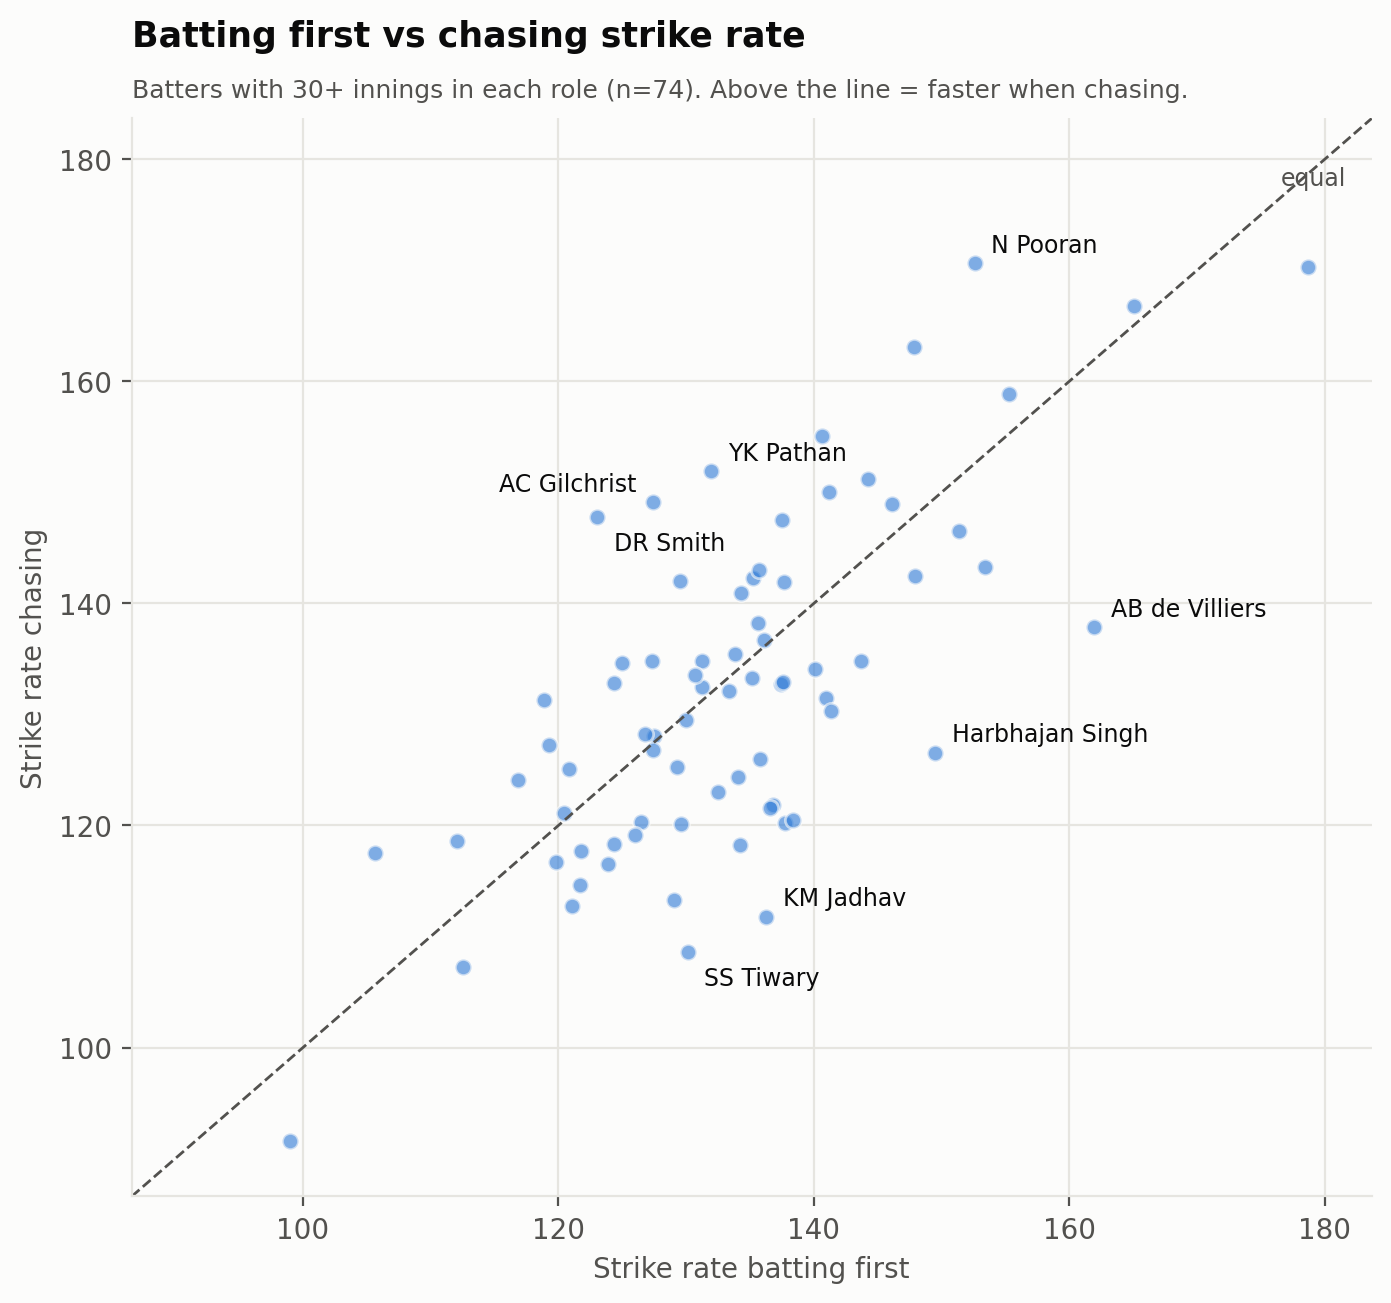

**6. Interpretation.** Median strike rate is 133.6 batting first vs 131.8 chasing (Wilcoxon p = 0.320); median runs per innings 23.0 vs 23.5 (p = 0.115). Chasing innings are cut short when the target is reached (median not-out rate 20% chasing vs 11% batting first), so lower runs per innings when chasing is expected and is NOT evidence of weaker batting. Individual differences (e.g. DR Smith +24.8) are not tested one by one to avoid multiple-comparison false positives.

**7. Limitations.** Chase innings are truncated by the target; strike rate is the fairer comparison.

In [9]:
show('A7')

## B. Bowling

### B1

**1. Question.** How does the rate and the type of wicket change across the innings?

**2. Metric.** balls per bowler wicket = legal balls / is_bowler_wicket; dismissal mix = share of bowler wickets by kind; chi-square test of independence between phase and dismissal kind.

**3. Calculation.** `b1_phase_wickets`

**4. Sample.** 11,795 bowler wickets from 251,319 legal balls.

,phase,balls,bowler_wkts,balls_per_bowler_wicket,economy,pct_bowled,pct_caught,pct_caught and bowled,pct_hit wicket,pct_lbw,pct_stumped
0,Powerplay,78656,2950,26.66,7.68,19.15,68.17,2.44,0.10,8.61,1.53
1,Middle,116079,4661,24.90,7.66,17.70,66.10,3.73,0.06,7.55,4.85
2,Death,56584,4184,13.52,9.77,19.46,70.77,2.89,0.22,4.59,2.08


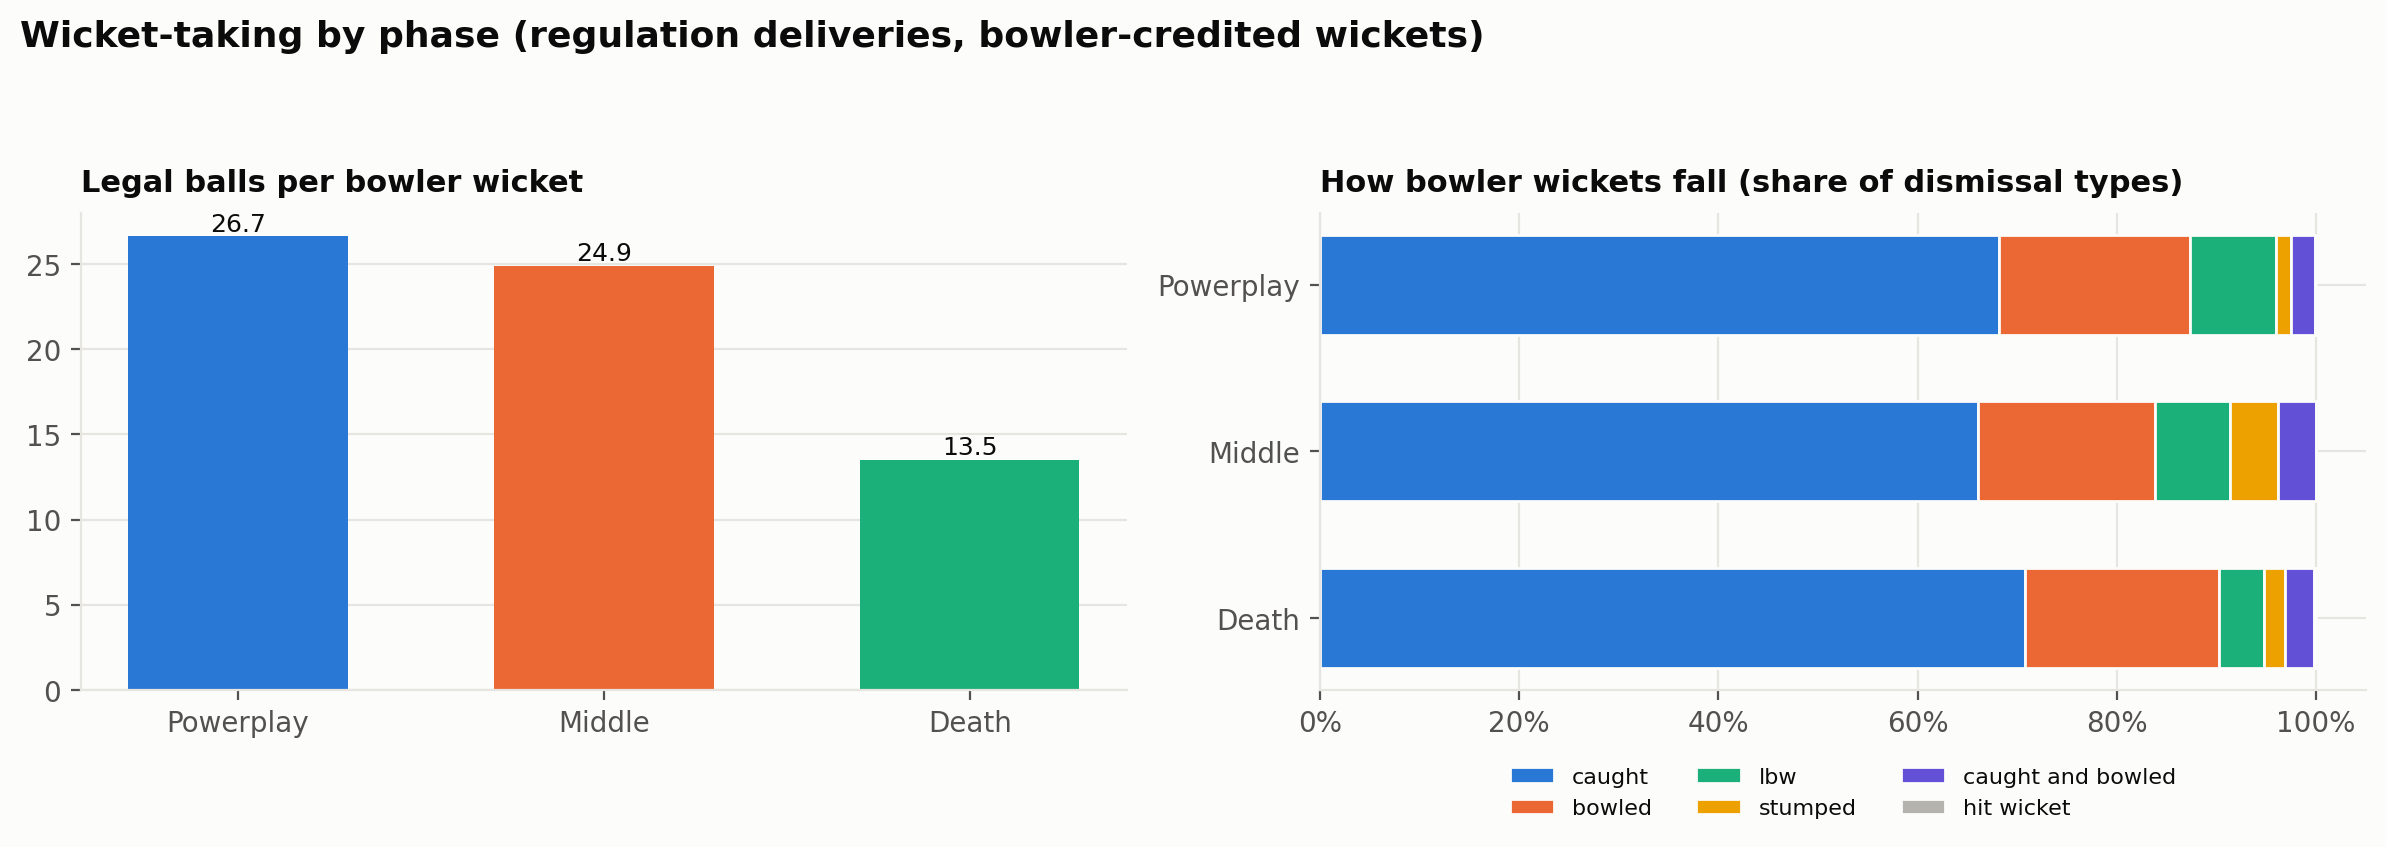

**6. Interpretation.** A bowler wicket falls every 13.5 balls at the death vs 26.7 in the Powerplay and 24.9 in the middle overs. The dismissal mix differs by phase (chi-square = 160, dof = 10, p = 3.9e-29): caught is 71% of death wickets vs 68% in the Powerplay; stumpings are 4.8% of middle-overs wickets vs 1.5% (Powerplay) and 2.1% (death), and bowled/lbw shares are highest in the Powerplay (28%). Bowler type is not in the data, so the link to spin in the middle overs is a plausible explanation, not a finding.

**7. Limitations.** Smallest expected cell count = 3.8 (hit wicket); chi-square assumption (>=5) NOT met for the rarest kind - result driven by large categories.

In [10]:
show('B1')

### B2

**1. Question.** Is there a trade-off between conceding few runs and taking wickets, once we adjust for when bowlers bowled?

**2. Metric.** Expected runs/wickets = each legal ball x league rate for that season AND phase. adj_economy = (runs - expected) x 6 / balls; wickets_vs_expected = wickets / expected. Spearman correlation.

**3. Calculation.** `b2_tradeoff`

**4. Sample.** Bowlers with >= 1000 legal balls (n = 76).

,bowler,legal_balls,economy,adj_economy,wickets,wickets_vs_expected,strike_rate
446,SP Narine,4075,6.73,-1.57,180,0.91,22.64
398,Rashid Khan,2859,6.82,-1.50,149,1.10,19.19
193,JJ Bumrah,3053,7.30,-1.42,165,1.01,18.50
438,SL Malinga,2828,7.14,-1.07,170,1.15,16.64
138,DW Steyn,2176,6.92,-1.01,97,0.94,22.43
263,M Muralitharan,1524,6.68,-0.98,63,0.93,24.19
71,B Kumar,3910,7.56,-0.97,181,0.92,21.60
355,R Ashwin,4524,7.12,-0.83,180,0.91,25.13
42,AR Patel,3099,7.28,-0.83,123,0.91,25.20
106,CV Varun,1590,7.55,-0.81,83,1.11,19.16


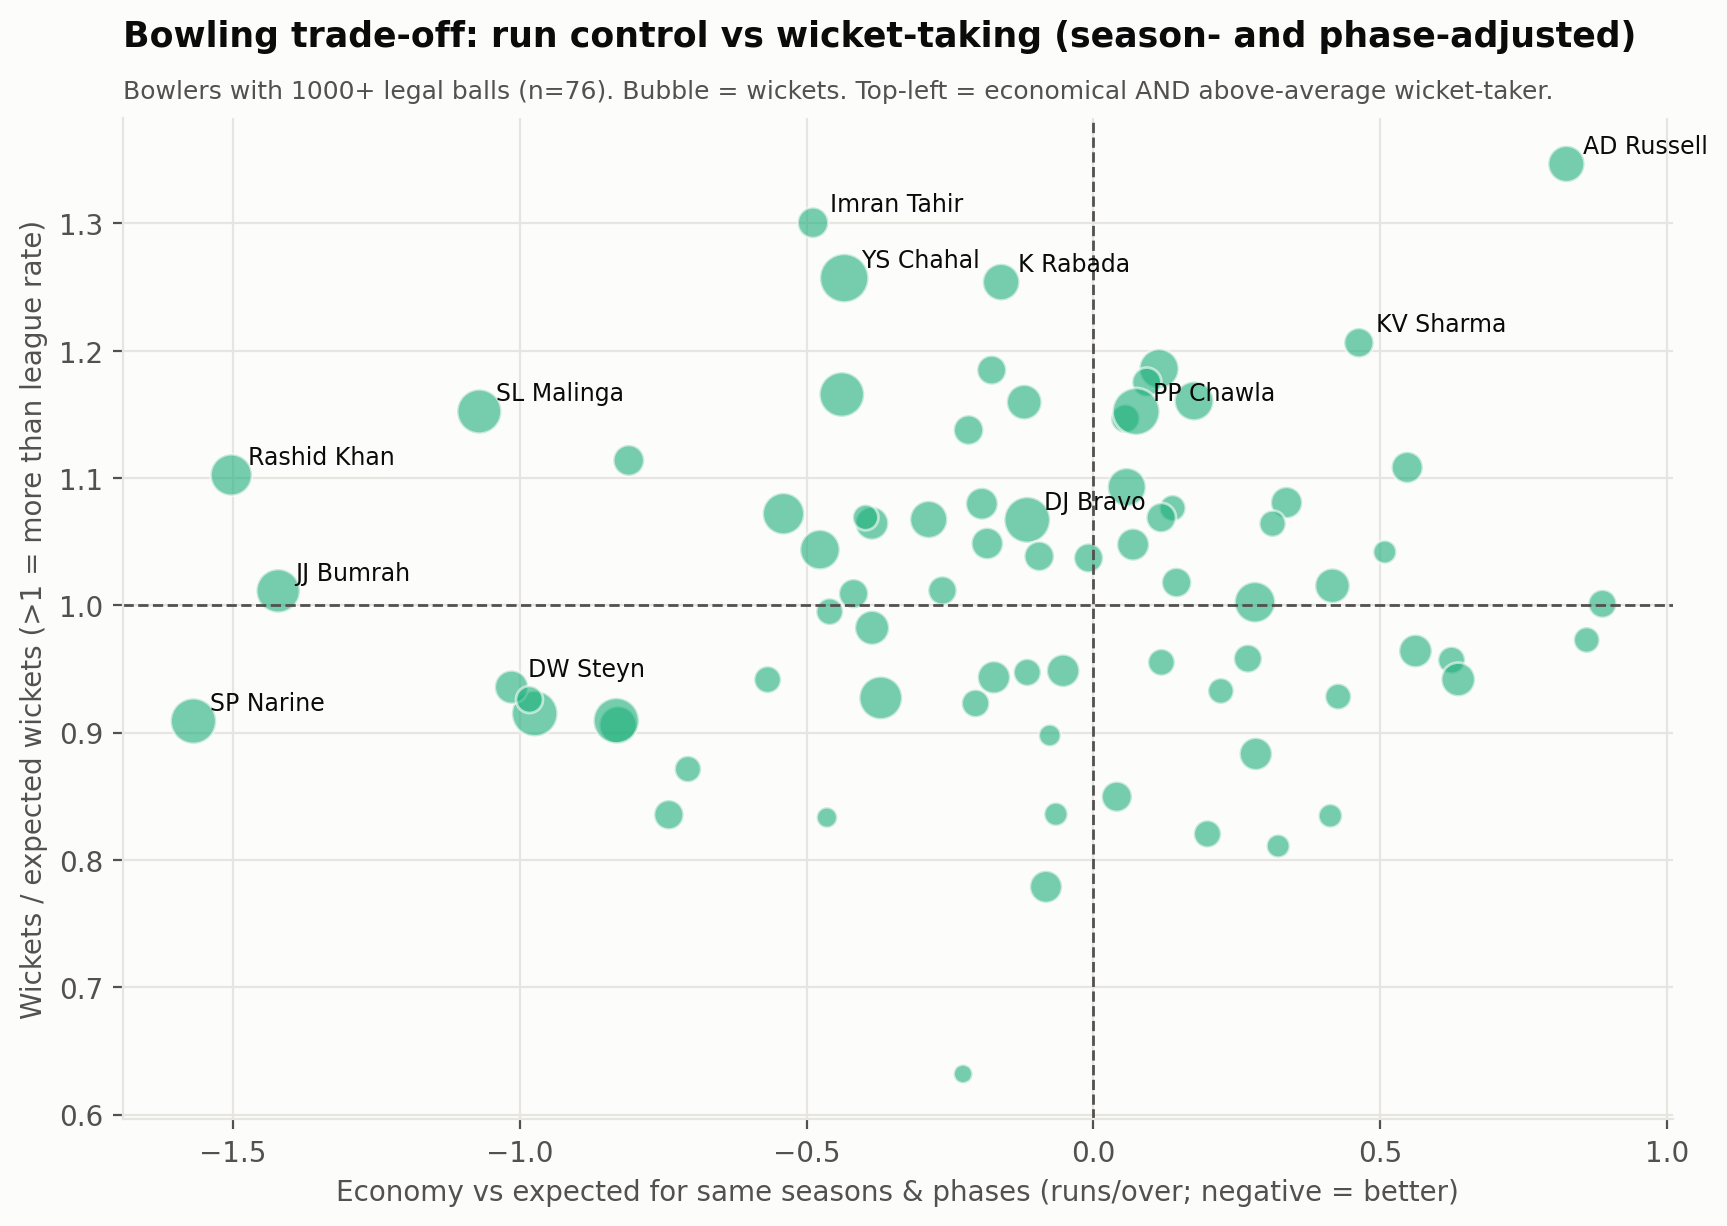

**6. Interpretation.** Phase/season adjustment changes the picture: SP Narine is the most economical relative to context (-1.57 runs/over). Across bowlers, the rank correlation between adjusted economy and strike rate is rho = -0.11 (p = 0.335) - no statistically significant trade-off: being economical neither costs nor guarantees wickets. 23 of 76 bowlers beat the league on BOTH measures (e.g. Rashid Khan, JJ Bumrah, SL Malinga, CV Varun, Harbhajan Singh).

**7. Limitations.** Adjustment uses phase and season only; batter quality and venue are not controlled.

In [11]:
show('B2')

### B3

In [12]:
show('B3')

**1. Question.** Which bowlers build pressure with dot balls, and which concede fewest boundaries?

**2. Metric.** dot % = legal balls with no runs scored / legal balls; boundary % = 4s + 6s off the bat / legal balls; Spearman correlation with economy.

**3. Calculation.** `b3_dot_boundary`

**4. Sample.** Bowlers with >= 1000 legal balls (n = 76).

,bowler,legal_balls,dot_pct,boundary_pct,economy
138,DW Steyn,2176,46.83,15.49,6.92
289,MM Patel,1355,43.54,17.79,7.52
262,M Morkel,1629,43.46,17.86,7.69
279,MG Johnson,1232,43.26,20.29,8.29
335,P Kumar,2524,42.59,17.51,7.73
129,DL Chahar,1669,42.42,19.23,7.98
483,TA Boult,2337,42.19,20.58,8.29
168,I Sharma,2309,41.97,19.97,8.24
386,RP Singh,1775,41.92,18.25,7.90
10,A Nehra,1908,41.82,18.61,7.85


**Fewest boundaries conceded**

,bowler,legal_balls,boundary_pct,dot_pct,economy
263,M Muralitharan,1524,11.15,39.24,6.68
355,R Ashwin,4524,11.47,34.31,7.12
356,R Bhatia,1636,11.49,26.65,7.41
446,SP Narine,4075,11.56,38.50,6.73
259,M Kartik,1149,12.01,33.25,7.25
398,Rashid Khan,2859,12.03,36.97,6.82
437,SK Warne,1194,12.31,35.68,7.27
8,A Mishra,3371,12.55,35.15,7.38
42,AR Patel,3099,12.55,32.88,7.28
221,KH Pandya,2122,12.58,31.86,7.37


**6. Interpretation.** DW Steyn has the highest dot-ball rate (46.8%); M Muralitharan concedes the fewest boundaries (11.2% of balls). Boundary % explains economy more strongly (rho = 0.87) than dot % (rho = -0.11): limiting boundaries matters more for run control than bowling dots. Note: dot % and boundary % are not era-adjusted (both shift with scoring levels).

**7. Limitations.** Fours/sixes proxy. Dot % counts legal balls with total_runs = 0 (leg-byes break a dot).

### B4

**1. Question.** Who are the most effective death bowlers once season scoring levels are removed?

**2. Metric.** adj_economy = (bowler runs - league runs expected for those seasons in this phase) x 6 / legal balls.

**3. Calculation.** `phase_specialists('Death')`

**4. Sample.** Bowlers with >= 600 legal balls in the death (n = 18).

,bowler,legal_balls,economy,adj_economy,wickets,strike_rate,dot_pct,boundary_pct
373,SP Narine,1021,7.40,-2.36,73,13.99,36.53,13.12
162,JJ Bumrah,1247,8.29,-1.65,91,13.70,30.95,15.32
365,SL Malinga,1117,7.86,-1.61,108,10.34,31.33,13.79
118,DW Steyn,634,8.30,-1.15,50,12.68,34.38,17.03
81,CH Morris,646,8.67,-1.10,58,11.14,28.33,16.56
437,YS Chahal,613,9.33,-0.84,59,10.39,28.55,17.13
62,B Kumar,1353,9.20,-0.72,100,13.53,26.46,18.40
102,DJ Bravo,1385,9.36,-0.39,115,12.04,28.74,18.41
442,Z Khan,607,9.05,-0.36,37,16.41,24.55,17.79
134,HV Patel,751,10.02,-0.07,73,10.29,30.49,20.77


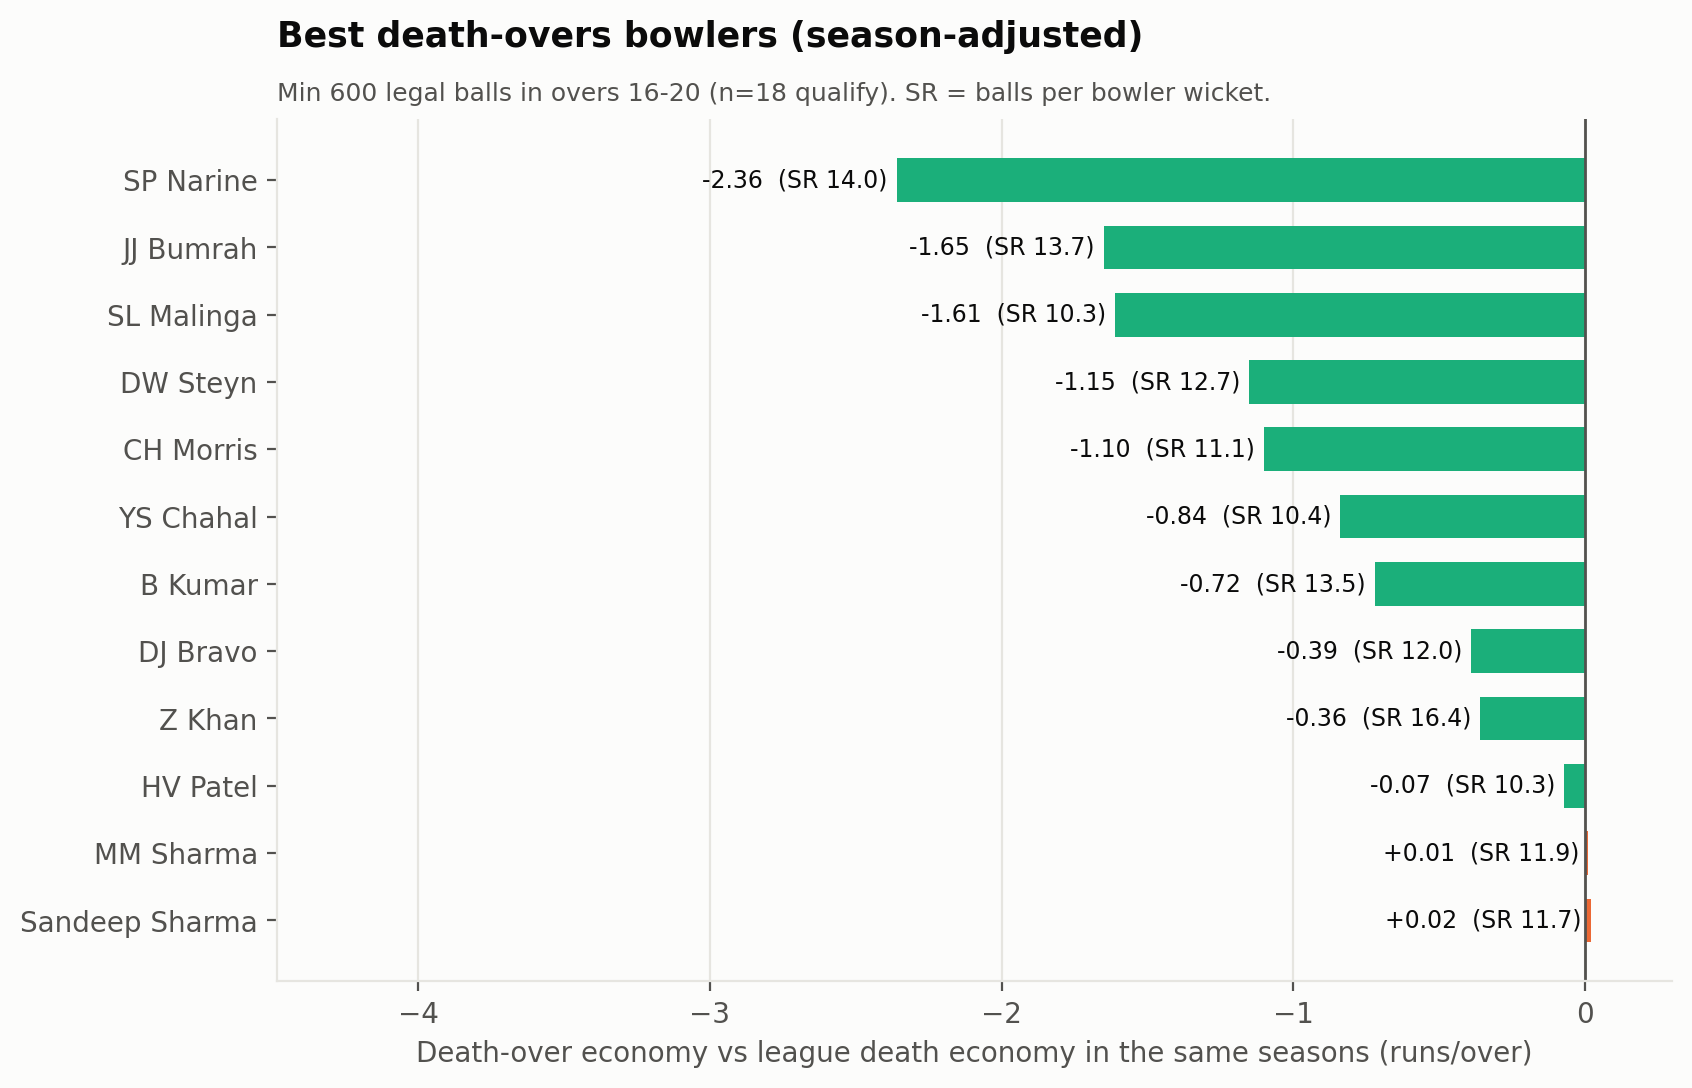

**6. Interpretation.** SP Narine is the standout death bowler (-2.36 runs/over vs league; raw economy 7.40, strike rate 14.0), then JJ Bumrah (-1.65) and SL Malinga (-1.61). 10 of 18 qualifying bowlers beat the league rate.

**7. Limitations.** Specialists are selected by captains for this phase - a survivor effect inflates their numbers.

In [13]:
show('B4')

### B5

In [14]:
show('B5')

**1. Question.** Who are the most effective powerplay bowlers once season scoring levels are removed?

**2. Metric.** adj_economy = (bowler runs - league runs expected for those seasons in this phase) x 6 / legal balls.

**3. Calculation.** `phase_specialists('Powerplay')`

**4. Sample.** Bowlers with >= 600 legal balls in the powerplay (n = 36).

,bowler,legal_balls,economy,adj_economy,wickets,strike_rate,dot_pct,boundary_pct
59,B Kumar,2153,6.39,-1.45,72,29.90,54.16,15.84
158,JJ Bumrah,1032,6.58,-1.35,34,30.35,52.13,15.79
361,SL Malinga,1111,6.26,-1.12,37,30.03,52.39,15.03
394,TA Boult,1428,7.05,-1.04,62,23.03,52.66,19.05
109,DW Steyn,1134,6.26,-0.99,34,33.35,55.03,15.34
368,SP Narine,918,6.85,-0.89,27,34.00,47.39,15.58
379,Sandeep Sharma,1614,6.99,-0.87,60,26.90,48.88,17.66
297,R Ashwin,1198,6.85,-0.74,49,24.45,43.49,13.94
431,Z Khan,1292,6.74,-0.66,52,24.85,49.30,16.87
282,P Kumar,1572,6.69,-0.58,40,39.30,51.65,16.35


**6. Interpretation.** B Kumar is the standout powerplay bowler (-1.45 runs/over vs league; raw economy 6.39, strike rate 29.9), then JJ Bumrah (-1.35) and SL Malinga (-1.12). 26 of 36 qualifying bowlers beat the league rate.

**7. Limitations.** Specialists are selected by captains for this phase - a survivor effect inflates their numbers.

### B6

In [15]:
show('B6')

**1. Question.** Which bowlers beat the league economy season after season?

**2. Metric.** Per qualifying season: economy minus league economy expected for that season and the phases bowled. Consistency = number of seasons better than the league, and SD of the season values.

**3. Calculation.** `b6_bowler_consistency`

**4. Sample.** Seasons with >= 120 legal balls; bowlers with >= 6 such seasons (n = 52).

,bowler,seasons,mean_adj_econ,sd_adj_econ,seasons_better_than_league,pct_seasons_better
34,R Ashwin,14,-0.83,0.57,14,100.00
44,SP Narine,13,-1.47,0.88,13,100.00
5,B Kumar,12,-0.94,0.49,12,100.00
37,RA Jadeja,15,-0.33,0.72,11,73.33
19,JJ Bumrah,9,-1.61,0.82,9,100.00
46,Sandeep Sharma,11,-0.41,0.81,9,81.82
40,Rashid Khan,8,-1.48,0.63,8,100.00
4,AR Patel,11,-0.75,0.69,8,72.73
22,KH Pandya,9,-0.74,0.56,8,88.89
13,Harbhajan Singh,11,-0.56,0.62,8,72.73


**6. Interpretation.** R Ashwin beat the league in 14 of 14 seasons (mean -0.83 runs/over). 7 bowler(s) beat the league in every qualifying season. The median bowler beat the league in 55% of seasons.

**7. Limitations.** Season samples are noisy: a season economy has a standard error of about 0.90 runs/over at 120 balls and 0.57 at 300 balls (per-ball SD 1.65).

### B7

In [16]:
show('B7')

**1. Question.** Does bowling change between the first and second innings, and between high- and low-scoring venues?

**2. Metric.** Economy and balls per bowler wicket by innings x phase; per-bowler paired comparison (Wilcoxon) of economy in innings 1 vs 2; venue tiers = terciles of season-adjusted first-innings score.

**3. Calculation.** `b7_conditions`

**4. Sample.** League: all regulation balls. Paired test: bowlers with >= 500 legal balls in each innings (n = 68). Venues: 15 with >= 20 full matches.

,phase,economy_inn1,economy_inn2,balls_per_wkt_inn1,balls_per_wkt_inn2
0,Death,10.03,9.42,13.62,13.40
1,Middle,7.66,7.66,25.74,24.10
2,Powerplay,7.52,7.83,27.76,25.65


**Venue scoring tiers**

,tier,balls,runs,w,dots,b4,economy,balls_per_wkt,dot_pct,boundary_pct
0,Low-scoring,44776,59720,2080,16104,7287,8.00,21.53,35.97,16.27
1,Mid,81358,108663,3757,29329,13428,8.01,21.66,36.05,16.50
2,High-scoring,89014,125451,4210,31430,16364,8.46,21.14,35.31,18.38


**6. Interpretation.** Bowling second, the median qualifying bowler's economy is 7.86 vs 8.05 bowling first (Wilcoxon p = 0.009, a statistically significant but small difference); second-innings totals are partly truncated by successful chases, which may contribute. Death-over wicket rates are similar in both innings (13.4 vs 13.6 balls per wicket). At high-scoring venues economy is 8.46 vs 8.00 at low-scoring venues, with boundary % 18.4% vs 16.3% and balls per wicket 21.1 vs 21.5.

**7. Limitations.** Second-innings bowling is affected by how the chase unfolds (truncated innings, required rate).

## C. Match pressure

### C1

**1. Question.** How does the size of the target change the chasing side's chance of winning?

**2. Metric.** Chase win % by first-innings score band; 95% Wilson intervals; split 2008-22 vs 2023-24.

**3. Calculation.** `c1_chase_by_target`

**4. Sample.** 1047 full, non-D/L, decided matches.

,period,first_innings,matches,chase_wins,chase_win_pct,ci_low,ci_high
0,All,<140,196,162,82.7,76.7,87.3
1,All,140-159,219,154,70.3,64.0,76.0
2,All,160-179,296,151,51.0,45.3,56.7
3,All,180-199,193,73,37.8,31.3,44.8
4,All,200+,143,26,18.2,12.7,25.3
5,2008-22,<140,184,153,83.2,77.1,87.9
6,2008-22,140-159,203,140,69.0,62.3,74.9
7,2008-22,160-179,261,131,50.2,44.2,56.2
8,2008-22,180-199,164,60,36.6,29.6,44.2
9,2008-22,200+,94,14,14.9,9.1,23.5


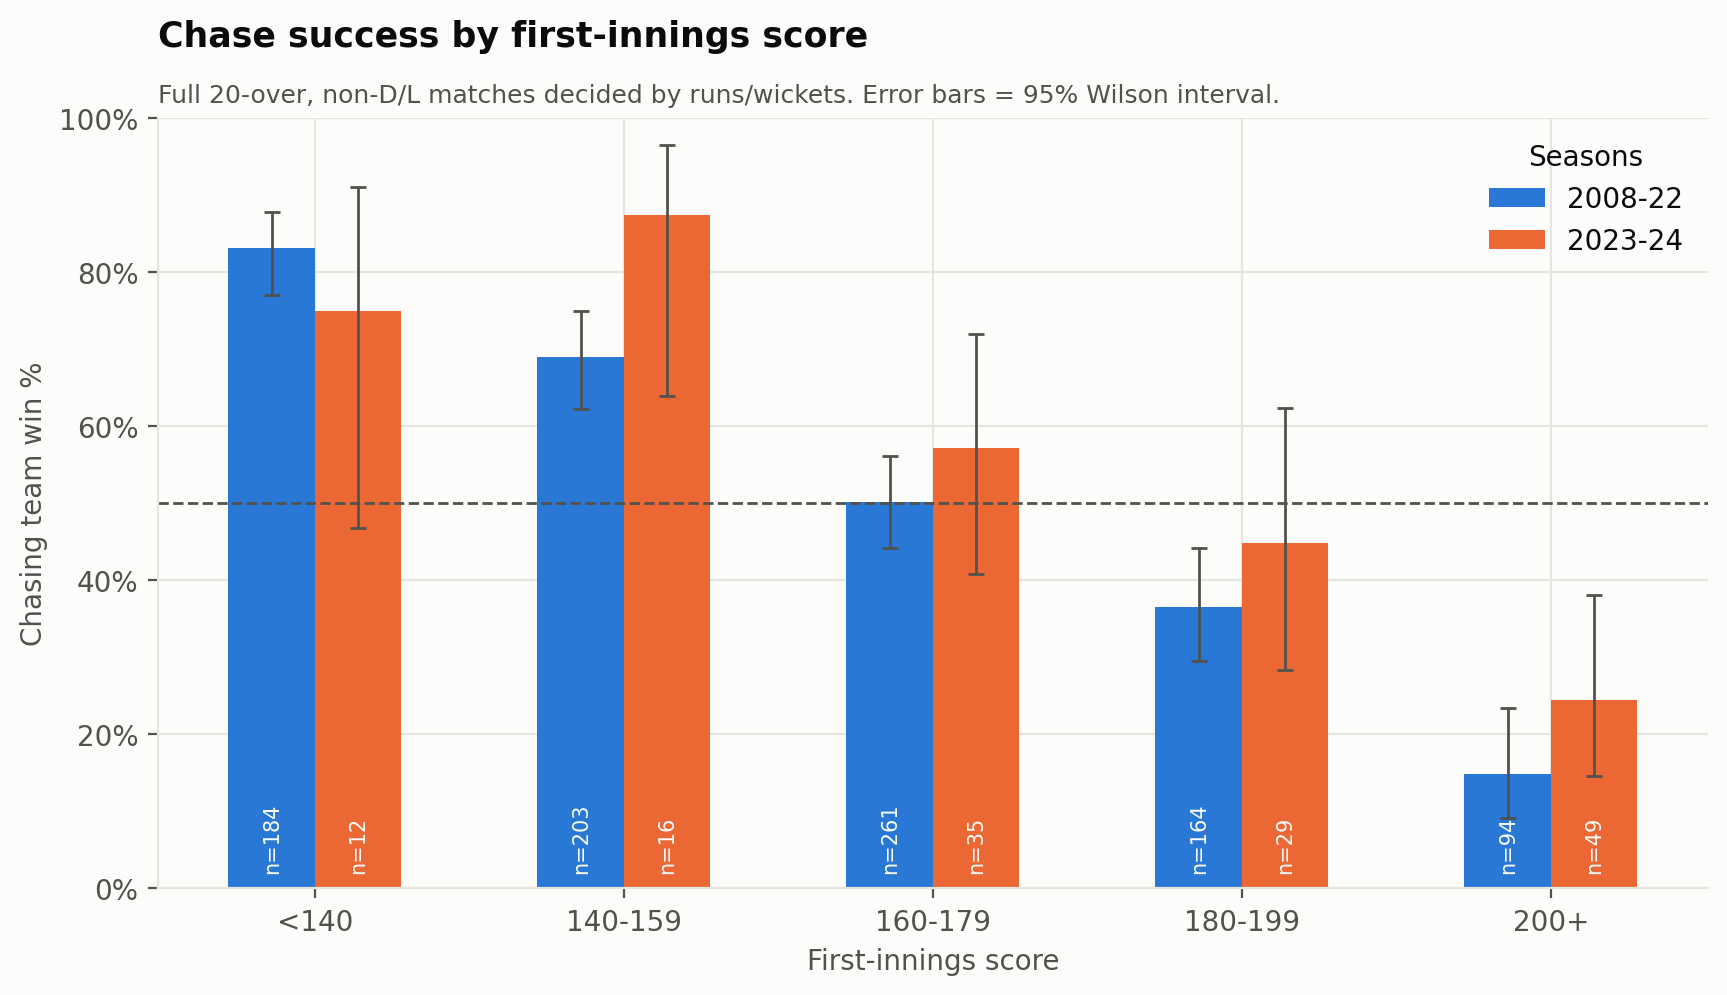

**6. Interpretation.** Chases of sub-140 totals succeed 83% of the time, falling to 51% for 160-179 and 18% for 200+ (n = 143). Chase success falls in every successive band. In 2023-24, targets of 180-199 were chased 45% of the time (n = 29, CI 28-62%) - the 'safe' total has moved upward with the scoring increase, though 2023-24 samples are small.

**7. Limitations.** Venue and team strength are not controlled.

In [17]:
show('C1')

### C2

**1. Question.** Given the situation part-way through a chase, how often does the chasing side win?

**2. Metric.** At the end of overs 6, 10 and 15 of a chase: required rate = runs needed / balls left x 6; wickets in hand = 10 - dismissals (retired hurt excluded). Win % per (required-rate band, wickets band); 95% Wilson CI.

**3. Calculation.** `c2_required_rate`

**4. Sample.** 1047 full non-D/L chases; 1037 still live after over 10. Cells with < 10 chases are omitted.

,after_over,required_rate,wickets_in_hand,states,chase_win_pct,ci_low,ci_high
0,6,<6,8-10,103,95.1,89.1,97.9
1,6,6-8,5-7,36,41.7,27.1,57.8
2,6,6-8,8-10,253,81.0,75.7,85.4
3,6,8-10,5-7,62,32.3,22.0,44.6
4,6,8-10,8-10,320,54.4,48.9,59.7
5,6,10-12,5-7,57,5.3,1.8,14.4
6,6,10-12,8-10,151,26.5,20.1,34.0
7,6,12-14,5-7,17,5.9,1.0,27.0
8,6,12-14,8-10,27,3.7,0.7,18.3
9,10,<6,5-7,24,91.7,74.2,97.7


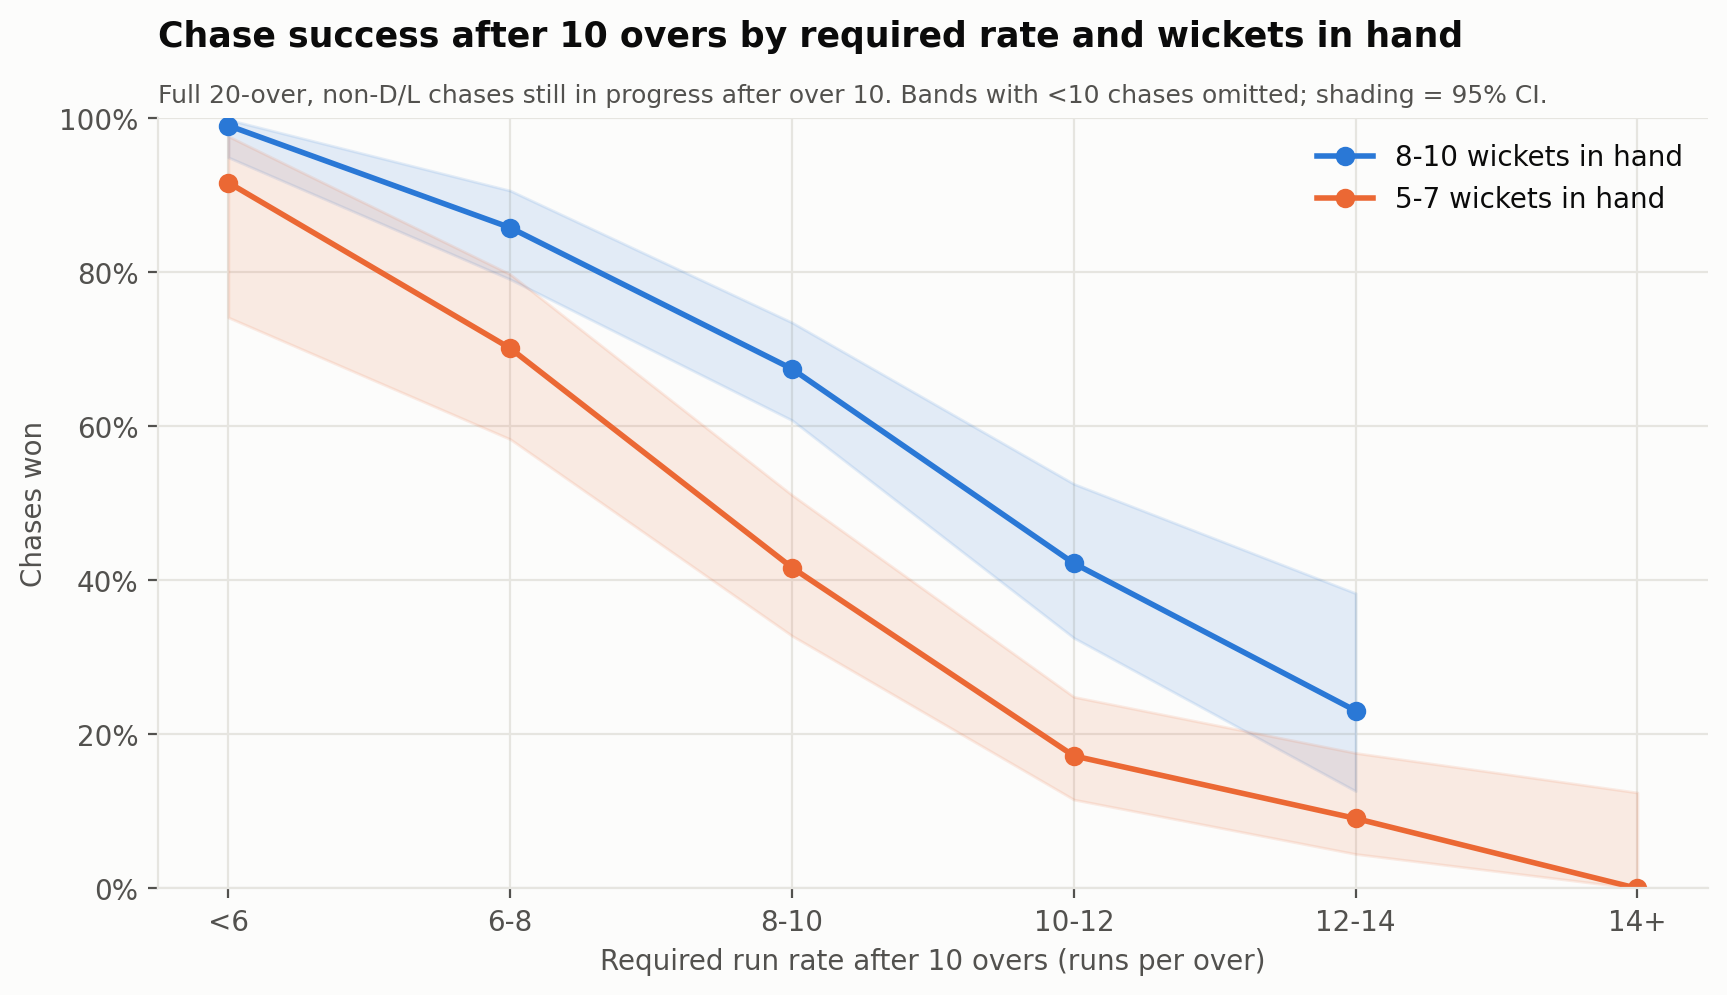

**6. Interpretation.** After 10 overs, needing 8-10 an over with 8-10 wickets in hand the chase is won 67% (n=206); with only 5-7 wickets in hand it falls to 42% (n=108). Needing 10-12 with 8-10 wickets: 42% (n=90). Both required rate and wickets in hand matter (rank correlation of required rate with winning at over 10: rho = -0.59). These are observed frequencies from real match states, not a modelled 'pressure index'.

**7. Limitations.** Each chase contributes one state per over shown, so cells at different overs are not independent.

In [18]:
show('C2')

### C3

**1. Question.** Do batting sides slow down as wickets fall, once the phase of the innings is held constant?

**2. Metric.** Wickets lost BEFORE each ball (cumulative is_player_out in the innings); run rate, boundary % and dot % by phase x wickets-lost band.

**3. Calculation.** `c3_wickets_remaining`

**4. Sample.** 250,618 legal balls in cells with >= 1,000 balls.

,phase,wkts_lost_band,balls,runs,b4,dots,run_rate,boundary_pct,dot_pct
0,Death,0-1,1888,3570,472,442,11.35,25.00,23.41
1,Death,2-3,14098,25213,3220,3497,10.73,22.84,24.80
2,Death,4-5,22540,38562,4724,5922,10.26,20.96,26.27
3,Death,6+,18058,26539,3090,6238,8.82,17.11,34.54
4,Middle,0-1,33543,46971,5168,9744,8.40,15.41,29.05
5,Middle,2-3,55830,72393,7603,17715,7.78,13.62,31.73
6,Middle,4-5,22336,26819,2696,7960,7.20,12.07,35.64
7,Middle,6+,4370,4472,436,1931,6.14,9.98,44.19
8,Powerplay,0-1,66282,88610,13374,30612,8.02,20.18,46.18
9,Powerplay,2-3,11673,13636,1983,5927,7.01,16.99,50.78


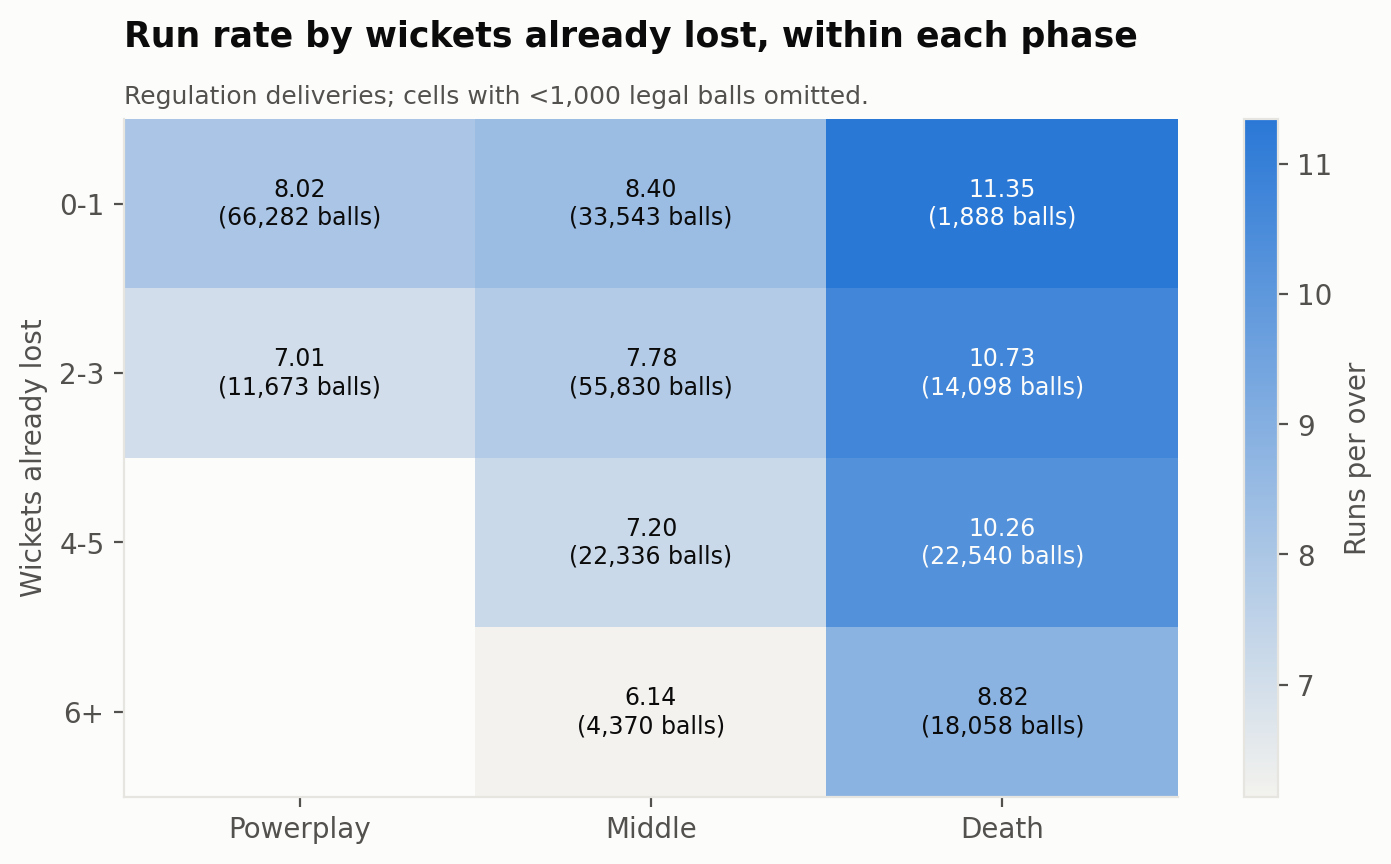

**6. Interpretation.** Within the same phase, losing wickets slows scoring: in the middle overs the run rate is 8.40 with 0-1 wickets down vs 6.14 with 6+ down; in the death overs 11.35 vs 8.82. Comparing within a phase matters - overall, death overs have both the most wickets down and the highest scoring, which would hide this effect.

**7. Limitations.** Association only: batting strength of the remaining batters is not observed.

In [19]:
show('C3')

### C4

**1. Question.** What distinguishes chases that succeed from those that fail, phase by phase?

**2. Metric.** Per chase and phase: run rate and wickets lost; medians compared with Mann-Whitney U tests.

**3. Calculation.** `c4_chase_patterns`

**4. Sample.** 566 won and 481 lost chases.

,phase,won_n,lost_n,median_rr_won,median_rr_lost,p_run_rate,mean_wkts_won,mean_wkts_lost,p_wickets
0,Powerplay,566,481,8.333,7.500,0.0,1.090,1.933,0.0
1,Middle,565,481,8.000,7.333,0.0,1.722,3.096,0.0
2,Death,504,472,10.667,8.400,0.0,1.149,3.025,0.0


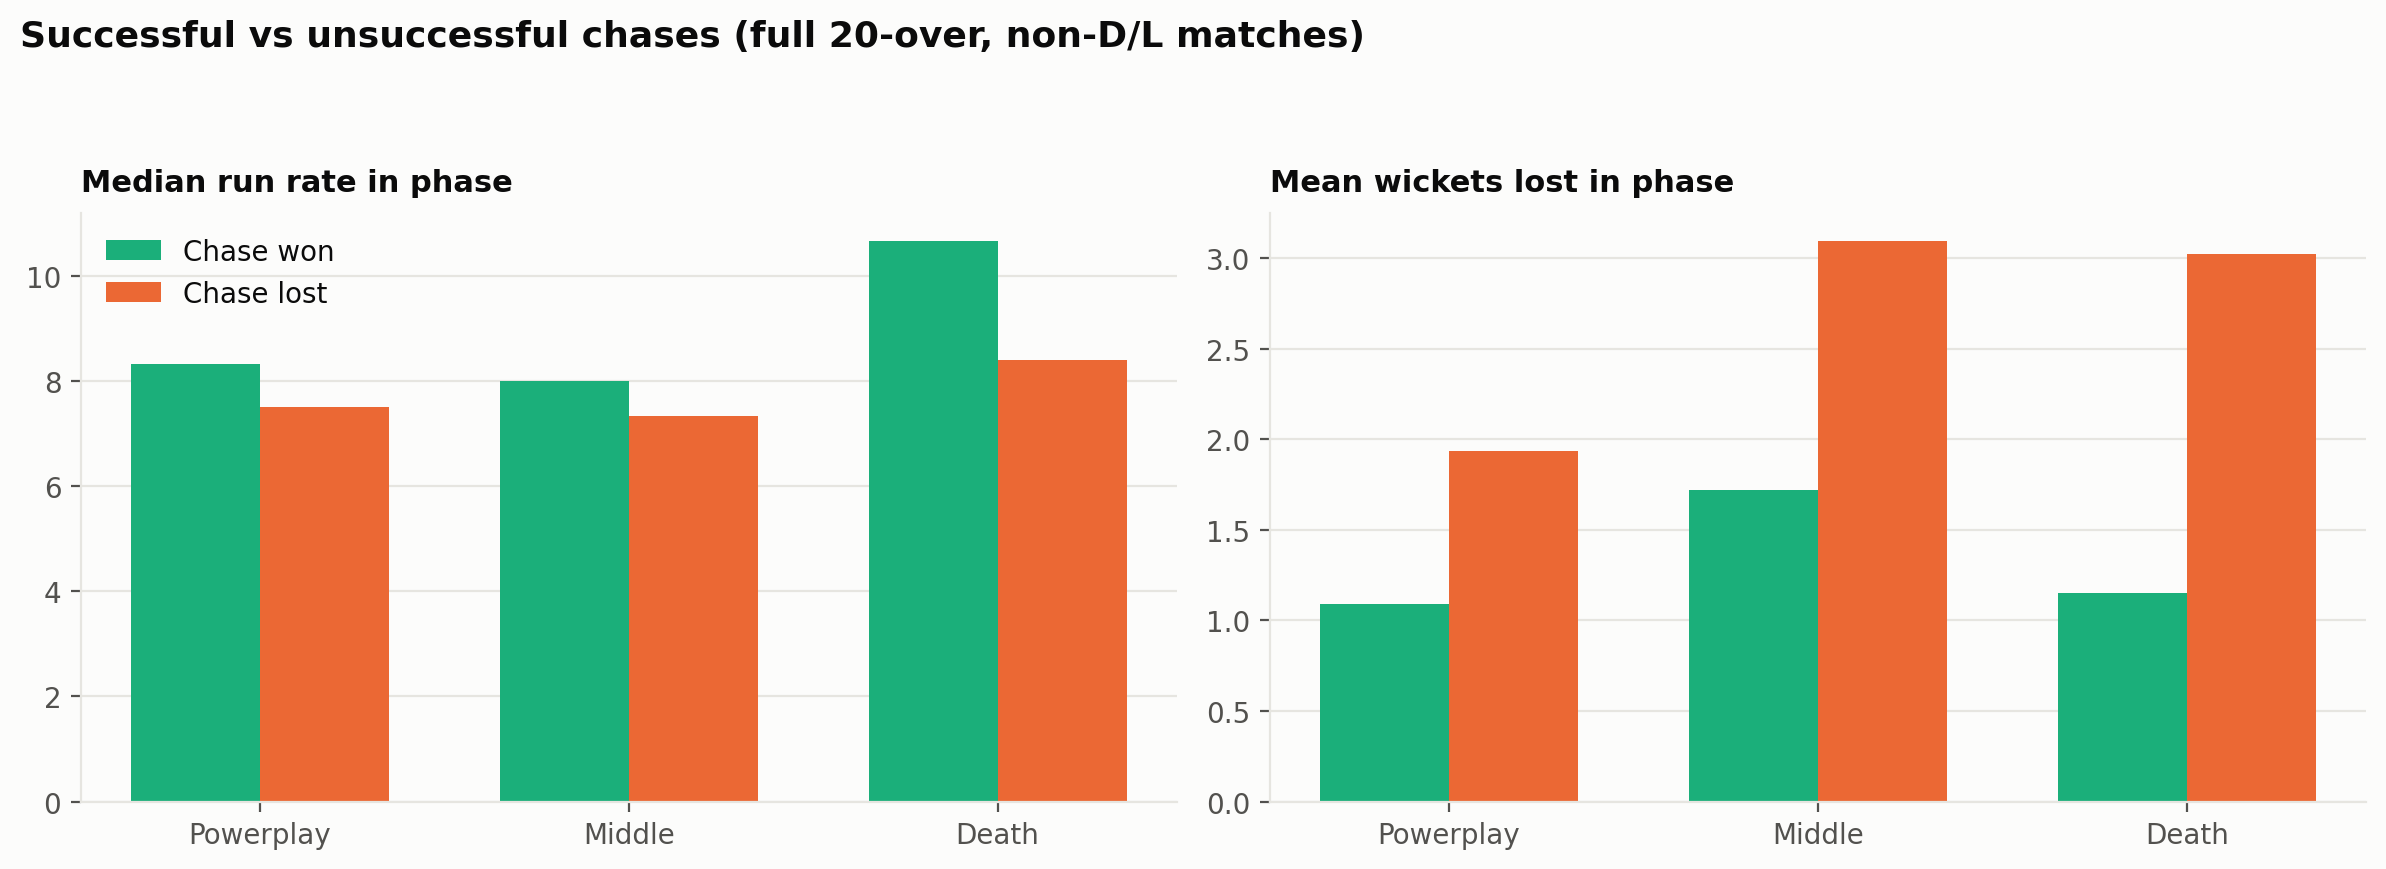

**6. Interpretation.** Successful chases are ahead from the start: Powerplay median run rate 8.33 vs 7.50, losing 1.09 vs 1.93 wickets on average (Mann-Whitney p = 1.5e-11 for run rate, 4.8e-33 for wickets). The biggest wicket gap is in the middle overs (1.72 vs 3.10). Caution: winning chases often end early, so their death-overs sample is smaller and selected (n = 504 vs 472).

**7. Limitations.** Outcome is partly defined by these same runs - this describes how wins happen, not what causes them.

In [20]:
show('C4')

### C5

In [21]:
show('C5')

**1. Question.** Are some teams genuinely better in tight finishes, or is it chance?

**2. Metric.** Close match = won by <= 10 runs, chase completed with <= 6 balls left (both non-D/L), or a tie. Close-match win % with 95% Wilson CI; chi-square test of homogeneity across teams; Spearman correlation with win % in other matches.

**3. Calculation.** `c5_close_matches`

**4. Sample.** 391 close matches; teams with >= 20 close matches (n = 10).

,team,close_matches,close_win_pct,ci_low,ci_high,other_win_pct,close_minus_other
4,Gujarat Titans,23,69.6,49.1,84.4,54.5,15.0
11,Rajasthan Royals,77,61.0,49.9,71.2,45.8,15.3
8,Mumbai Indians,91,54.9,44.7,64.8,55.3,-0.3
0,Chennai Super Kings,87,52.9,42.5,63.0,61.3,-8.5
13,Royal Challengers Bengaluru,88,48.9,38.7,59.1,48.8,0.1
2,Delhi Capitals,84,48.8,38.4,59.3,44.6,4.2
10,Punjab Kings,91,45.1,35.2,55.3,45.8,-0.8
6,Kolkata Knight Riders,88,44.3,34.4,54.7,56.4,-12.1
14,Sunrisers Hyderabad,68,42.6,31.6,54.5,51.8,-9.1
1,Deccan Chargers,29,37.9,22.7,56.0,39.1,-1.2


**6. Interpretation.** Gujarat Titans have the best close-match record (69.6% of 23, CI 49-84%) and Deccan Chargers the worst (37.9%). But only 0 team(s) have an interval excluding 50%, and the chi-square test does not reject 'all teams equal' (p = 0.13). Close-match and other-match win % correlate at rho = 0.30 (p = 0.40). The data does not support a 'clutch team' effect beyond what chance explains.

**7. Limitations.** Close matches are a small, outcome-defined subset; team rosters change each season.

### C6

In [22]:
show('C6')

**1. Question.** How does play differ in matches decided by narrow margins, and do individual batters change?

**2. Metric.** League run rate and balls per bowler wicket by phase in close vs other matches; per-batter strike rate in close vs other matches (Wilcoxon signed-rank).

**3. Calculation.** `c6_narrow_margin_players`

**4. Sample.** 391 close matches. Batters with >= 150 balls in close matches and >= 500 in others (n = 91).

,player,balls_close,sr_close,balls_other,sr_other,sr_diff
18,DJ Hussey,527.0,138.0,548.0,108.6,29.4
26,IK Pathan,409.0,136.9,537.0,107.8,29.1
52,N Pooran,301.0,179.4,789.0,155.8,23.6
12,CL White,246.0,142.3,509.0,118.7,23.6
49,MP Stoinis,564.0,155.1,750.0,132.1,23.0
17,DJ Hooda,493.0,138.5,638.0,122.6,16.0
81,Tilak Varma,245.0,136.7,545.0,150.6,-13.9
80,TM Dilshan,258.0,101.6,749.0,119.0,-17.4
85,VR Iyer,296.0,124.7,671.0,142.6,-18.0
46,MEK Hussey,427.0,108.4,1185.0,127.8,-19.3


**League by phase**

,phase,run_rate_other,run_rate_close,balls_per_wkt_other,balls_per_wkt_close
0,Death,9.70,10.35,13.13,14.16
1,Middle,7.81,7.75,24.02,26.63
2,Powerplay,7.86,7.85,25.34,29.42


**6. Interpretation.** Run rate in close vs other matches by phase: Powerplay 7.85 vs 7.86; Middle 7.75 vs 7.81; Death 10.35 vs 9.70 - close matches score faster at the death, where narrow finishes are decided. For batters, median strike rate in close matches is 133.2 vs 131.0 otherwise (Wilcoxon p = 0.640). Individual 'big-match' differences such as DJ Hussey (+29.4) come from 150-400 balls and are within normal sampling noise.

**7. Limitations.** Closeness is defined by the result, so it is not a pre-match condition.

### C7

**1. Question.** How does scoring in overs 16-20 differ between chases that are won and lost?

**2. Metric.** Run rate and wickets per over for overs 16-20, restricted to chases still live after over 15; required rate at the end of over 15.

**3. Calculation.** `c7_final_overs`

**4. Sample.** 976 chases live after over 15 (504 won).

,chase_won,over_number,runs,balls,matches,w,run_rate,wkts_per_over
0,0,16,3896,2808,472,234,8.32,0.50
1,0,17,3984,2758,466,234,8.67,0.50
2,0,18,3926,2684,452,306,8.78,0.68
3,0,19,3655,2584,440,295,8.49,0.67
4,0,20,3400,2341,412,359,8.71,0.87
5,1,16,4733,2968,504,146,9.57,0.29
6,1,17,4627,2806,481,128,9.89,0.27
7,1,18,4623,2536,447,130,10.94,0.29
8,1,19,3774,1927,376,123,11.75,0.33
9,1,20,2109,823,228,52,15.38,0.23


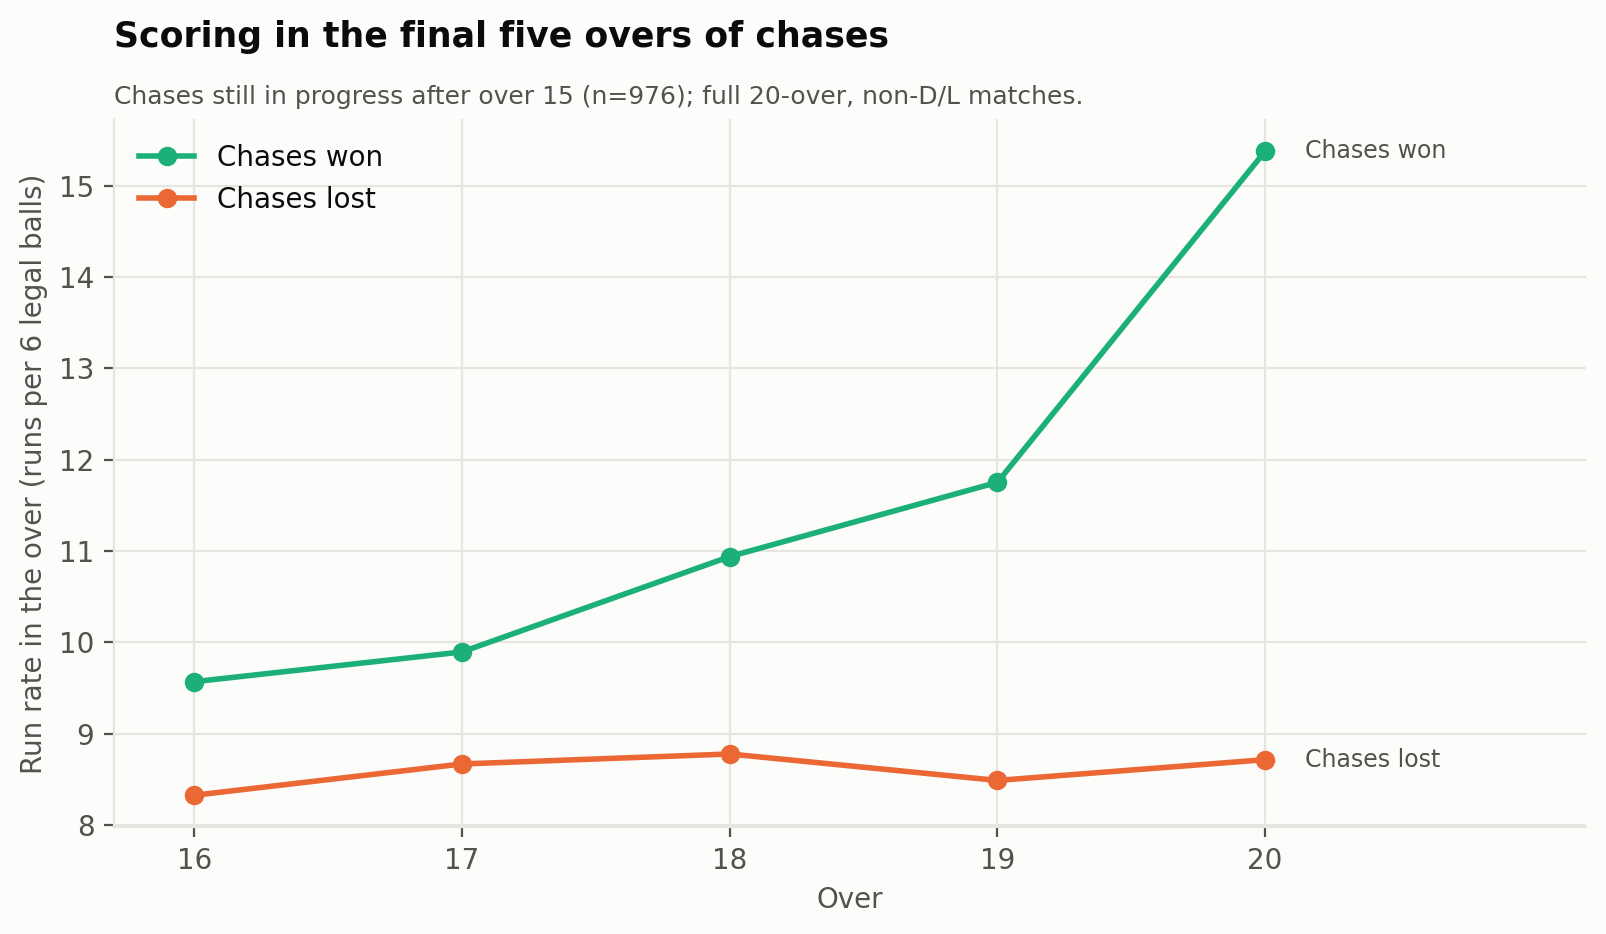

**6. Interpretation.** Chases that were eventually won needed a median 7.40 per over from over 16, vs 13.60 for those lost: the gap in match position before the final five overs is already large. In the final overs, winning chases scored at 11.51 per over on average vs 8.59 for losing chases; losing chases also lost 0.64 wickets per over vs 0.28 for winning chases. Winning chases often finish before over 20, so later overs include fewer winning matches.

**7. Limitations.** Survivorship: the set of matches changes over by over as chases end.

In [23]:
show('C7')

## D. Team contribution

### D1

**1. Question.** Where in the innings does each franchise gain or lose runs relative to the league?

**2. Metric.** Per team and phase: runs per over minus the league rate expected for the same seasons and phase; share of team runs by phase.

**3. Calculation.** `d1_team_phase_scoring`

**4. Sample.** All regulation deliveries; 15 franchises.

phase,team,Powerplay,Middle,Death
0,Royal Challengers Bengaluru,-0.12,0.11,0.59
1,Chennai Super Kings,-0.08,0.06,0.49
2,Mumbai Indians,-0.06,-0.00,0.44
3,Gujarat Lions,0.63,0.15,-0.63
4,Kolkata Knight Riders,0.07,0.07,-0.01
5,Punjab Kings,0.12,0.18,-0.23
6,Deccan Chargers,0.14,-0.10,-0.20
7,Delhi Capitals,0.13,-0.12,-0.26
8,Rajasthan Royals,-0.09,0.09,-0.30
9,Gujarat Titans,-0.51,-0.19,0.37


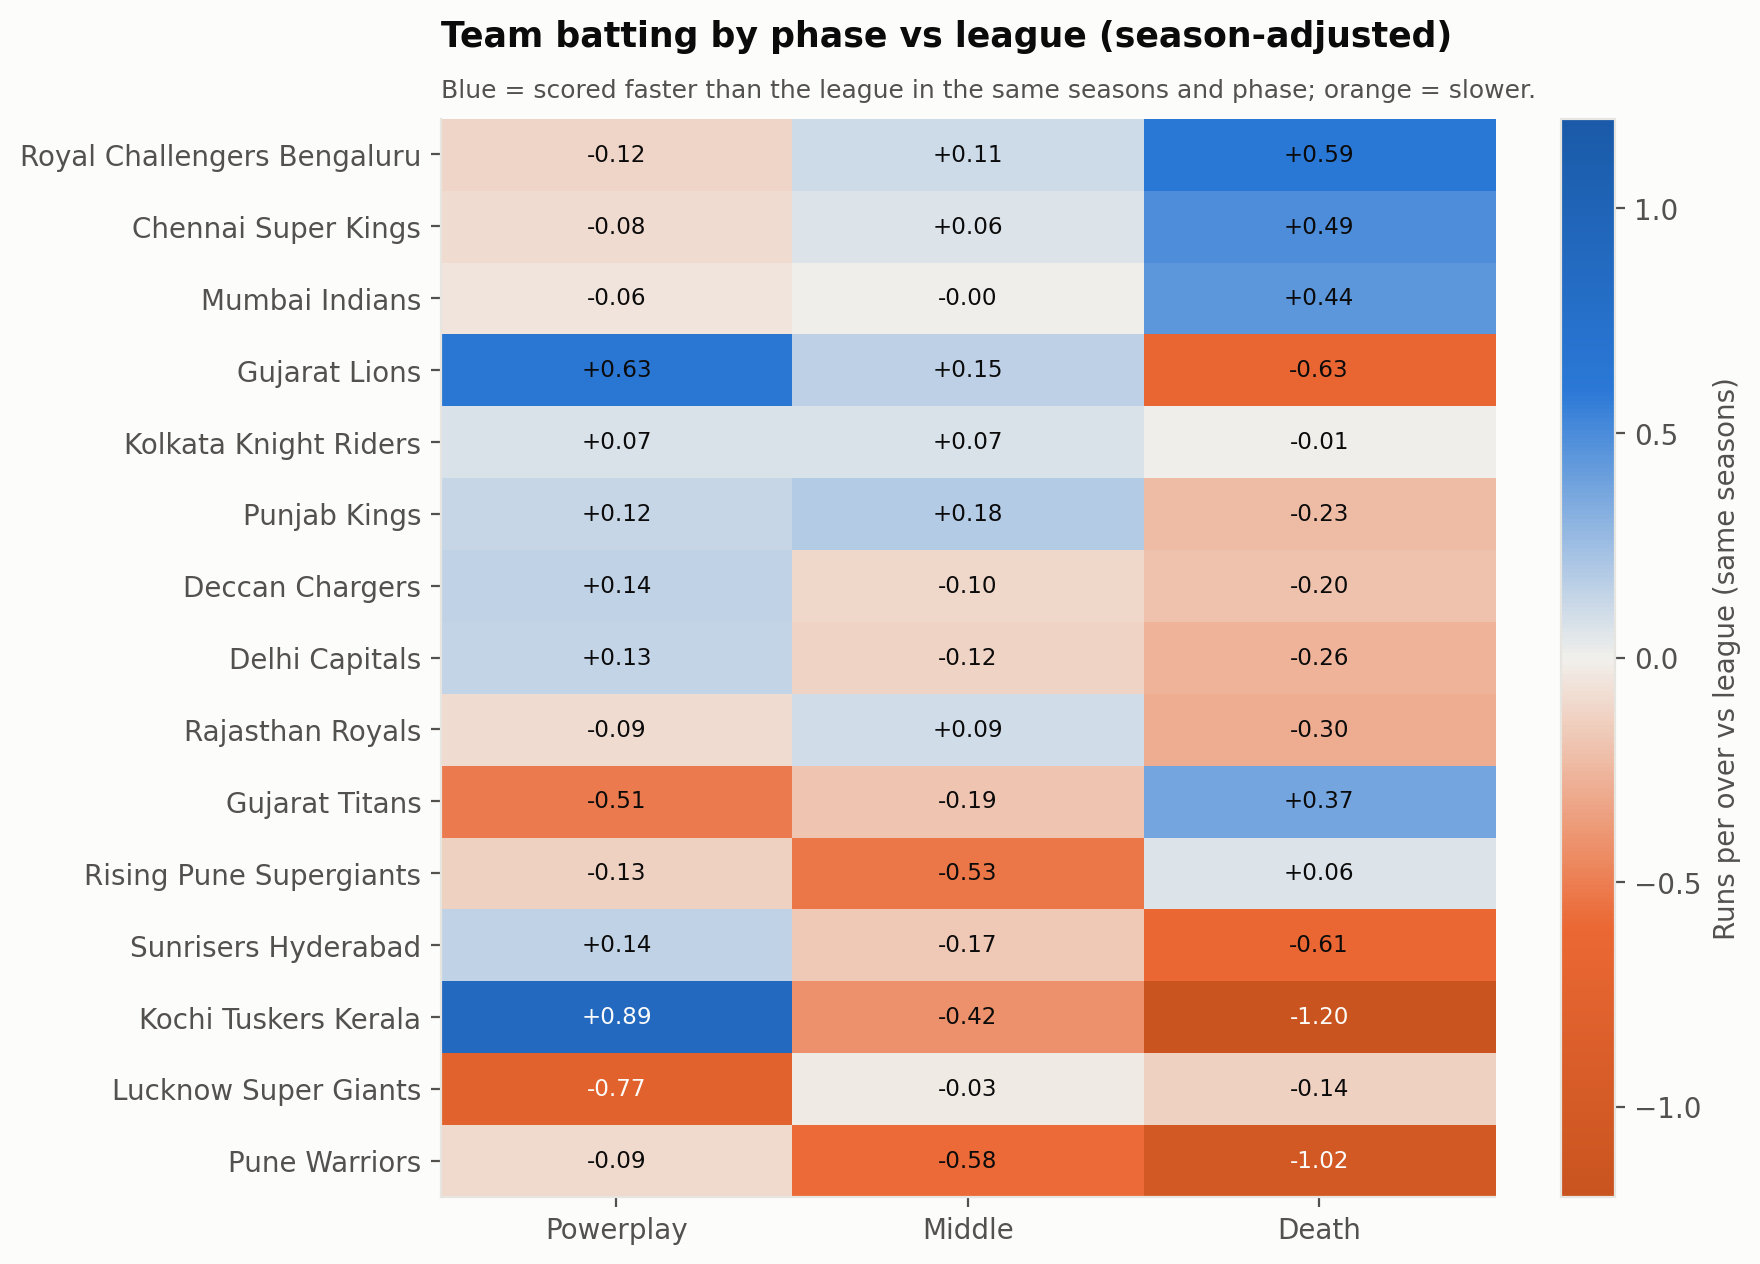

**6. Interpretation.** Best phase-adjusted batting: Powerplay - Kochi Tuskers Kerala (+0.89); Middle - Punjab Kings (+0.18); Death - Royal Challengers Bengaluru (+0.59 runs/over). Run shares are similar across teams (Powerplay 28-36% of runs), so differences are in efficiency rather than structure.

**7. Limitations.** Short-lived franchises have small samples (2-5 seasons).

In [24]:
show('D1')

### D2

**1. Question.** Which franchises take wickets more often than the league, and in which phase?

**2. Metric.** Bowler wickets per 120 legal balls minus the league rate expected for the same seasons and phase.

**3. Calculation.** `d2_team_phase_wickets`

**4. Sample.** All regulation deliveries; 15 franchises.

phase,team,Powerplay,Middle,Death
0,Gujarat Titans,0.65,0.07,0.88
1,Rising Pune Supergiants,0.12,0.34,0.81
2,Chennai Super Kings,0.30,0.25,0.39
3,Mumbai Indians,0.17,0.16,0.11
4,Deccan Chargers,0.48,-0.12,0.04
5,Royal Challengers Bengaluru,-0.03,0.01,0.15
6,Punjab Kings,-0.26,-0.18,0.40
7,Delhi Capitals,-0.16,0.00,-0.01
8,Sunrisers Hyderabad,-0.21,-0.03,0.04
9,Kolkata Knight Riders,-0.23,0.21,-0.27


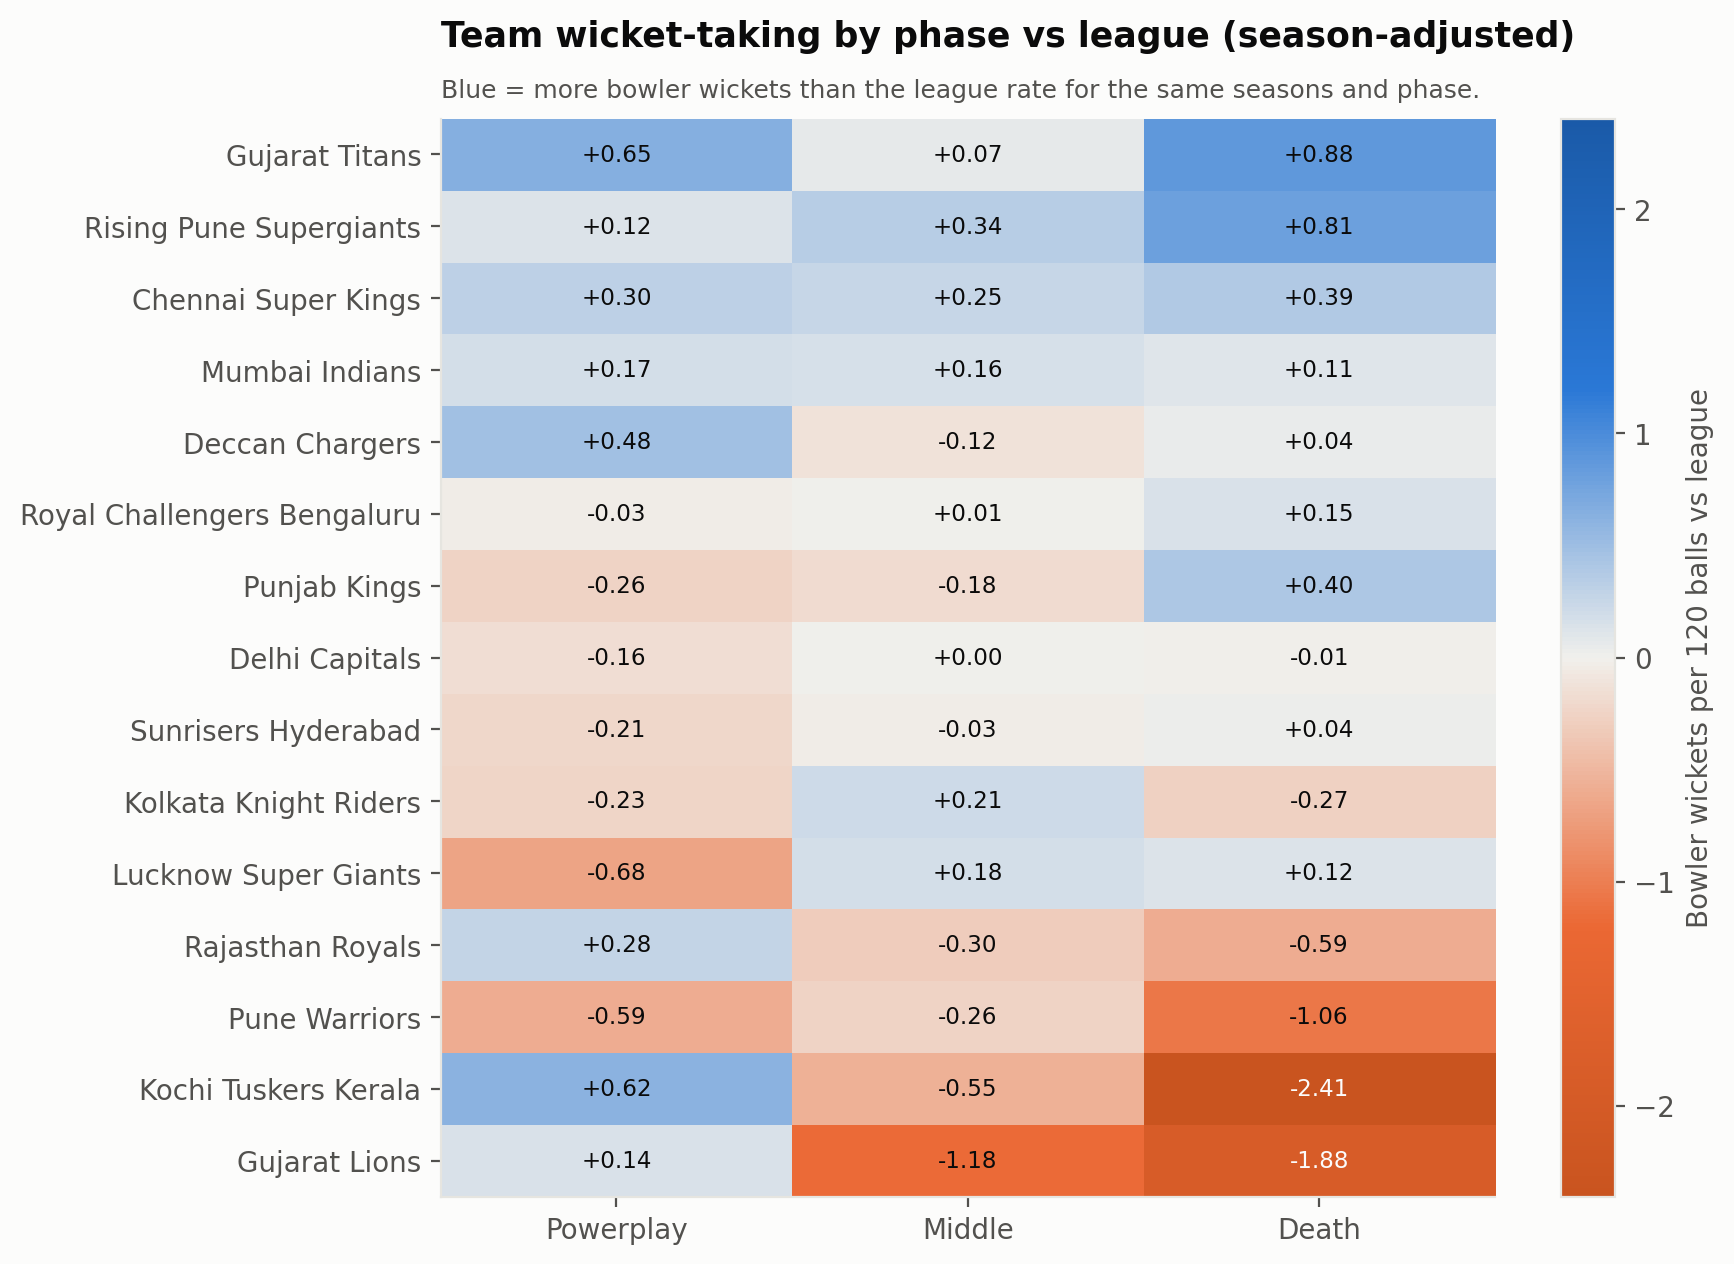

**6. Interpretation.** Most wicket-taking relative to the league: Powerplay - Gujarat Titans (+0.65 per 120 balls); Middle - Rising Pune Supergiants (+0.34 per 120 balls); Death - Gujarat Titans (+0.88 per 120 balls). The spread is about +/-2.4 wickets per 120 balls.

**7. Limitations.** Bowler-credited wickets only (run-outs excluded).

In [25]:
show('D2')

### D3

**1. Question.** How do franchises compare with the league in batting and bowling, and does that explain winning?

**2. Metric.** Batting = run rate minus league expectation for the same seasons and phases; bowling = runs conceded per over minus expectation; net = batting - bowling. Spearman correlation of net with win %.

**3. Calculation.** `d3_strengths`

**4. Sample.** All 15 franchises (regulation deliveries).

,team,batting_rr_vs_league,bowling_econ_vs_league,net_vs_league,win_pct,seasons,decided
0,Chennai Super Kings,0.115,-0.165,0.279,58.228,15,237
8,Mumbai Indians,0.083,-0.093,0.176,55.172,17,261
6,Kolkata Knight Riders,0.053,-0.096,0.149,52.191,17,251
12,Rising Pune Supergiants,-0.273,-0.401,0.128,50.000,2,30
4,Gujarat Titans,-0.160,-0.237,0.076,62.222,3,45
14,Sunrisers Hyderabad,-0.175,-0.157,-0.019,48.352,12,182
13,Royal Challengers Bengaluru,0.144,0.174,-0.031,48.810,17,252
11,Rajasthan Royals,-0.049,0.017,-0.067,51.142,15,219
5,Kochi Tuskers Kerala,-0.135,-0.034,-0.100,42.857,1,14
2,Delhi Capitals,-0.074,0.052,-0.126,46.000,17,250


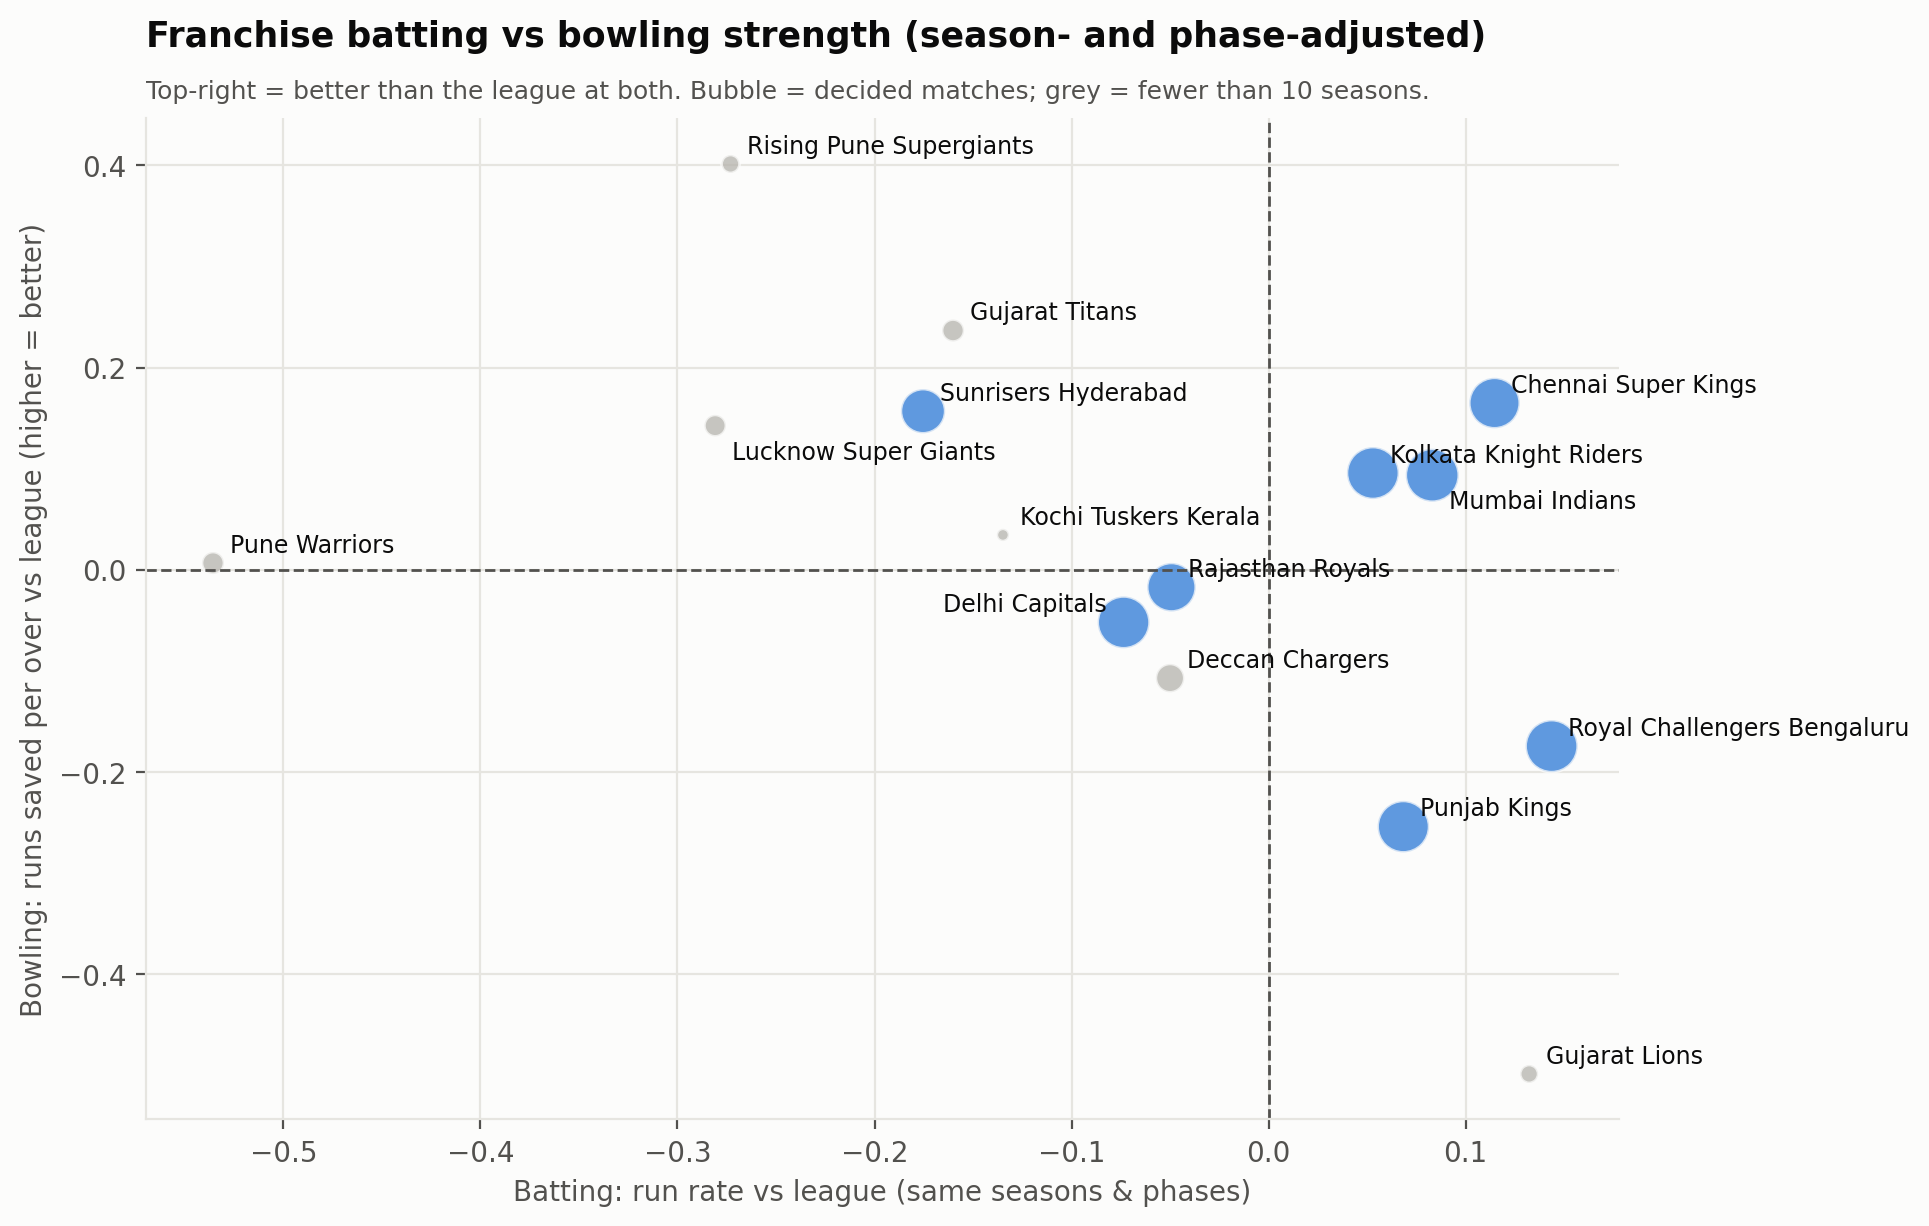

**6. Interpretation.** Chennai Super Kings have the best net rating (+0.28 runs/over: batting +0.11, bowling -0.16). Net rating tracks win % closely (rho = 0.75, p = 0.001, n = 15; established franchises only: rho = 0.90, n = 8) - run-rate differential is a sound summary of team quality.

**7. Limitations.** Ignores venue and opposition strength.

In [26]:
show('D3')

### D4

**1. Question.** Which franchises are consistently strong, and how much of the season-to-season swing is just chance?

**2. Metric.** Win % per season; SD across seasons; compared with the SD expected from binomial chance alone (sqrt(p(1-p)/n)) given ~14-16 matches per season.

**3. Calculation.** `d4_team_consistency`

**4. Sample.** Franchises with >= 10 seasons (n = 8).

,team,seasons,mean_win_pct,sd_win_pct,best,worst,seasons_above_50,sd_expected_by_chance,sd_excess_over_chance
0,Chennai Super Kings,15,57.8,11.0,68.8,28.6,12,12.4,-1.4
13,Royal Challengers Bengaluru,17,48.2,11.2,62.5,23.1,8,13.0,-1.8
11,Rajasthan Royals,15,50.5,11.4,81.2,35.7,5,13.1,-1.7
10,Punjab Kings,17,45.0,12.4,70.6,21.4,2,13.1,-0.6
6,Kolkata Knight Riders,17,51.7,13.0,78.6,23.1,9,13.0,0.0
14,Sunrisers Hyderabad,12,47.6,13.0,64.7,21.4,5,12.8,0.2
8,Mumbai Indians,17,54.1,13.8,70.6,28.6,9,12.7,1.1
2,Delhi Capitals,17,45.4,15.0,66.7,14.3,5,13.0,2.0


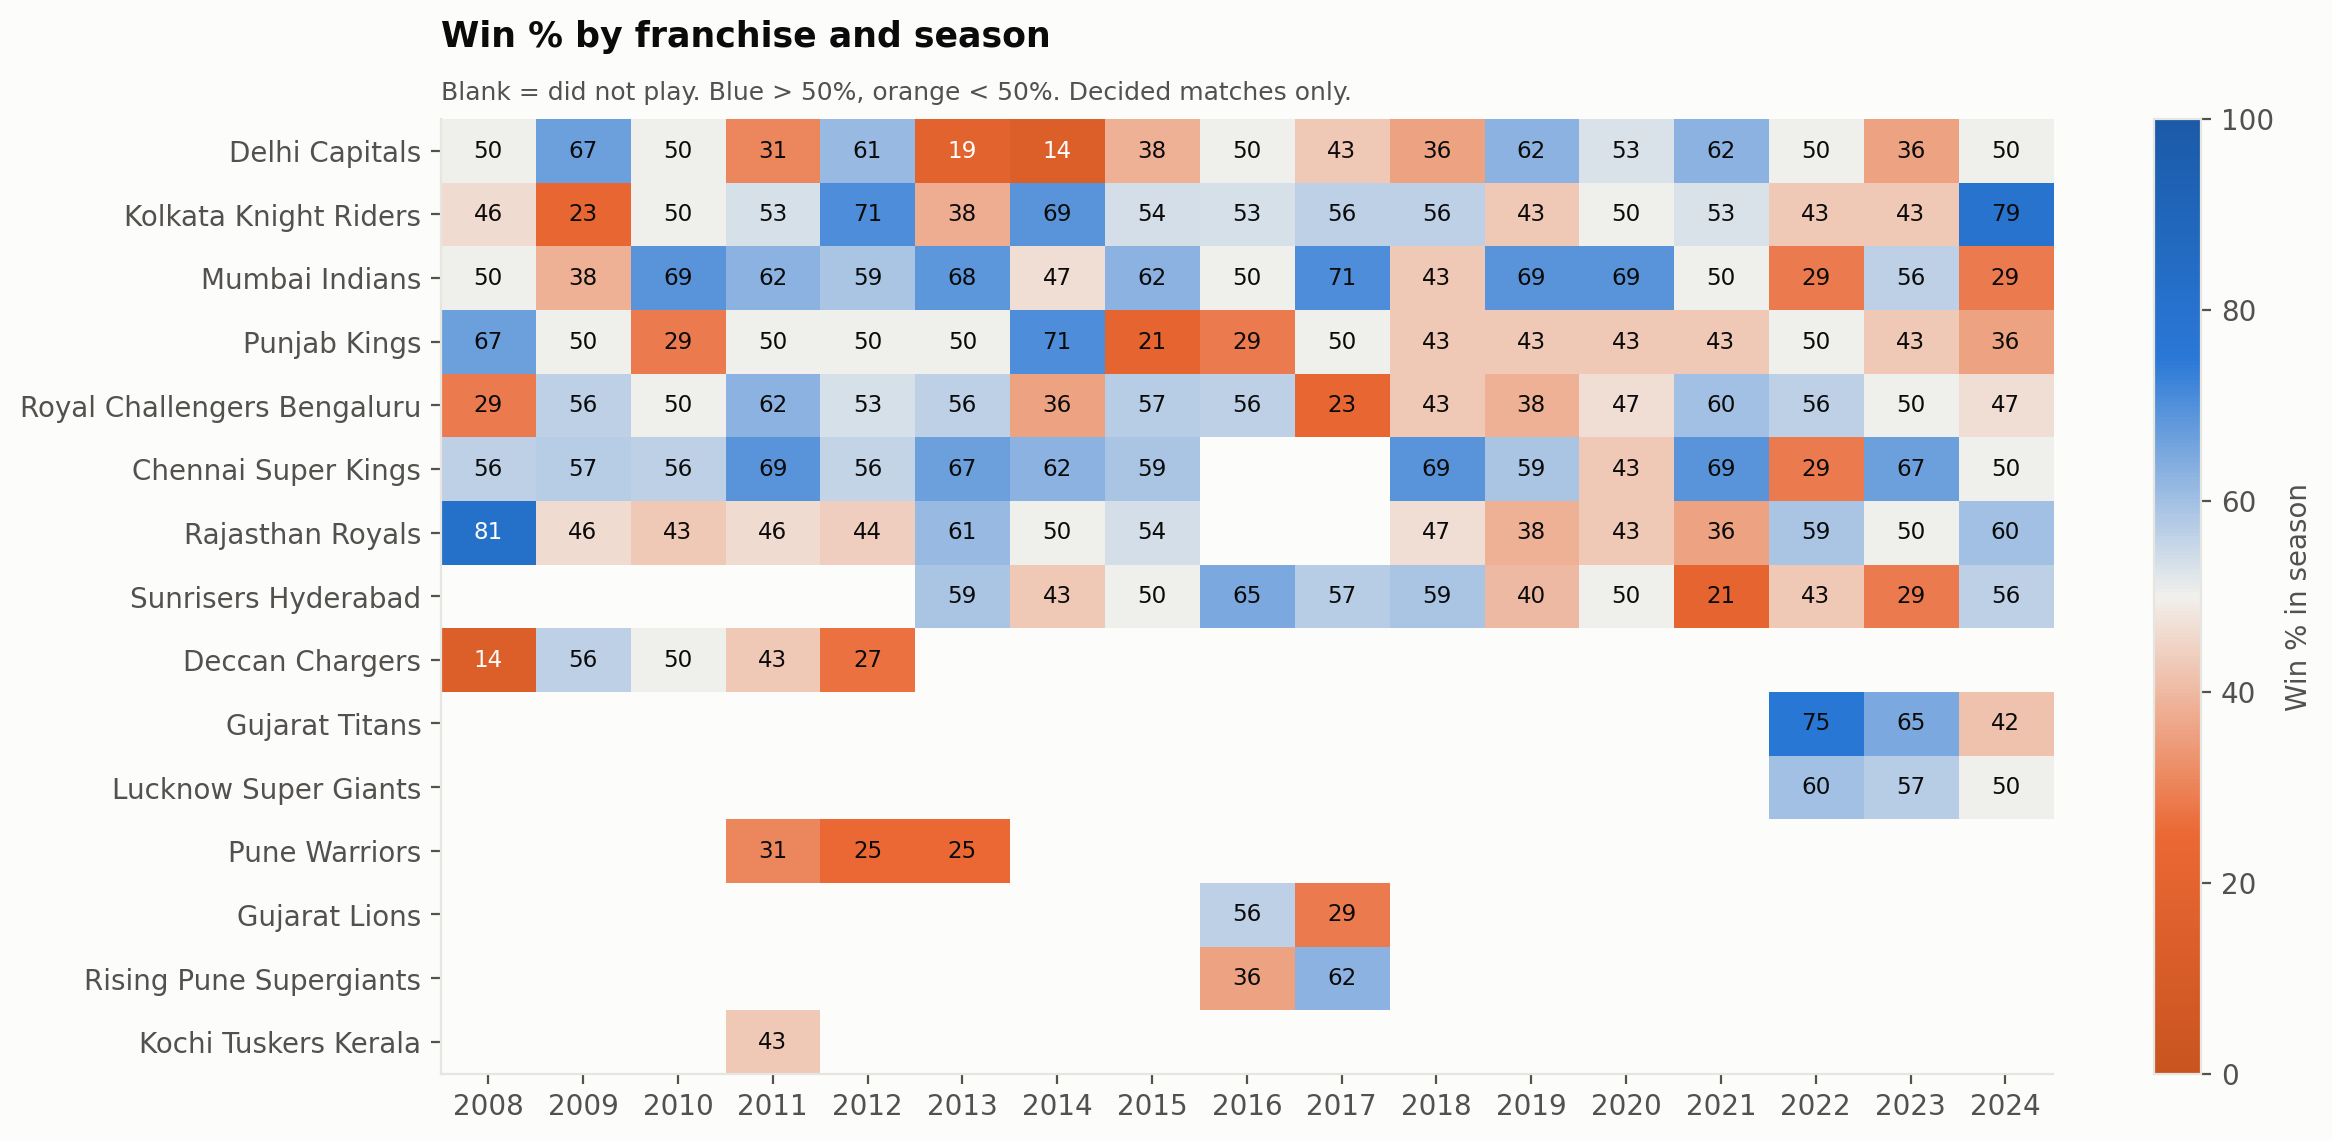

**6. Interpretation.** Chennai Super Kings are the most consistent (season win % SD 11.0, above 50% in 12 of 15 seasons); Delhi Capitals the least (SD 15.0). Binomial chance alone, with ~15 matches a season, would produce an SD of about 13 points. Observed SDs (11-15) exceed this for 4 of 8 franchises, so most season-to-season swings in win % are of the size chance alone produces; the season-level record is a noisy guide to underlying strength.

**7. Limitations.** Season win % rests on ~14-16 matches.

In [27]:
show('D4')

### D5

In [28]:
show('D5')

**1. Question.** When a side batting first goes on to win, how does its innings differ from one that loses?

**2. Metric.** First innings only (not truncated by a target), full 20-over non-D/L matches: median run rate, wickets, dot % and boundary % per phase for eventual winners vs losers; Mann-Whitney U per phase.

**3. Calculation.** `d5_win_vs_loss`

**4. Sample.** 1061 first innings.

,phase,batting_side_won,innings,median_rr,mean_wkts,dot_pct,boundary_pct,p_run_rate
0,Death,0,571,9.40,2.62,29.64,18.31,0.0
1,Death,1,489,10.80,2.43,24.99,23.94,0.0
2,Middle,0,572,7.11,2.41,34.37,11.97,0.0
3,Middle,1,489,8.33,2.01,28.89,15.37,0.0
4,Powerplay,0,572,7.33,1.60,49.47,17.76,0.0
5,Powerplay,1,489,8.00,1.11,45.23,20.65,0.0


**6. Interpretation.** Winning first innings outscore losing ones in every phase; the gap is largest in the Death overs (median 10.80 vs 9.40 per over). Winners lose fewer middle-overs wickets (2.01 vs 2.41) and hit more boundaries at the death (23.9% vs 18.3% of balls). Mann-Whitney p-values for run rate: Powerplay 2.2e-12, Middle 6.0e-26, Death 1.7e-20.

**7. Limitations.** The outcome also depends on the second innings; this describes associations within the first innings.

### D6

**1. Question.** How has the way teams score changed between the early and the recent IPL?

**2. Metric.** Run rate, sixes and fours per over, dot % and balls per dismissal by era and phase.

**3. Calculation.** `d6_eras`

**4. Sample.** All 260,759 regulation deliveries; eras 2008-12, 2013-17, 2018-22, 2023-24.

,era,phase,runs,balls,b4,b6,dots,w,run_rate,sixes_per_over,fours_per_over,dot_pct,balls_per_wkt
0,2008-12,Death,25729,16346,1927,1105,4587,1395,9.44,0.41,0.71,28.06,11.72
1,2008-12,Middle,42350,34114,3078,1278,11487,1436,7.45,0.22,0.54,33.67,23.76
2,2008-12,Powerplay,28649,23137,3550,703,11475,945,7.43,0.18,0.92,49.60,24.48
3,2013-17,Death,26500,16025,1920,1316,4474,1370,9.92,0.49,0.72,27.92,11.70
4,2013-17,Middle,42326,33048,3025,1401,10637,1380,7.68,0.25,0.55,32.19,23.95
5,2013-17,Powerplay,28587,22523,3520,708,10628,889,7.62,0.19,0.94,47.19,25.34
6,2018-22,Death,27959,16624,1984,1502,4893,1391,10.09,0.54,0.72,29.43,11.95
7,2018-22,Middle,43768,33464,2941,1680,10657,1449,7.85,0.30,0.53,31.85,23.09
8,2018-22,Powerplay,29943,22588,3532,958,10377,856,7.95,0.25,0.94,45.94,26.39
9,2023-24,Death,13696,7589,950,802,2145,628,10.83,0.63,0.75,28.26,12.08


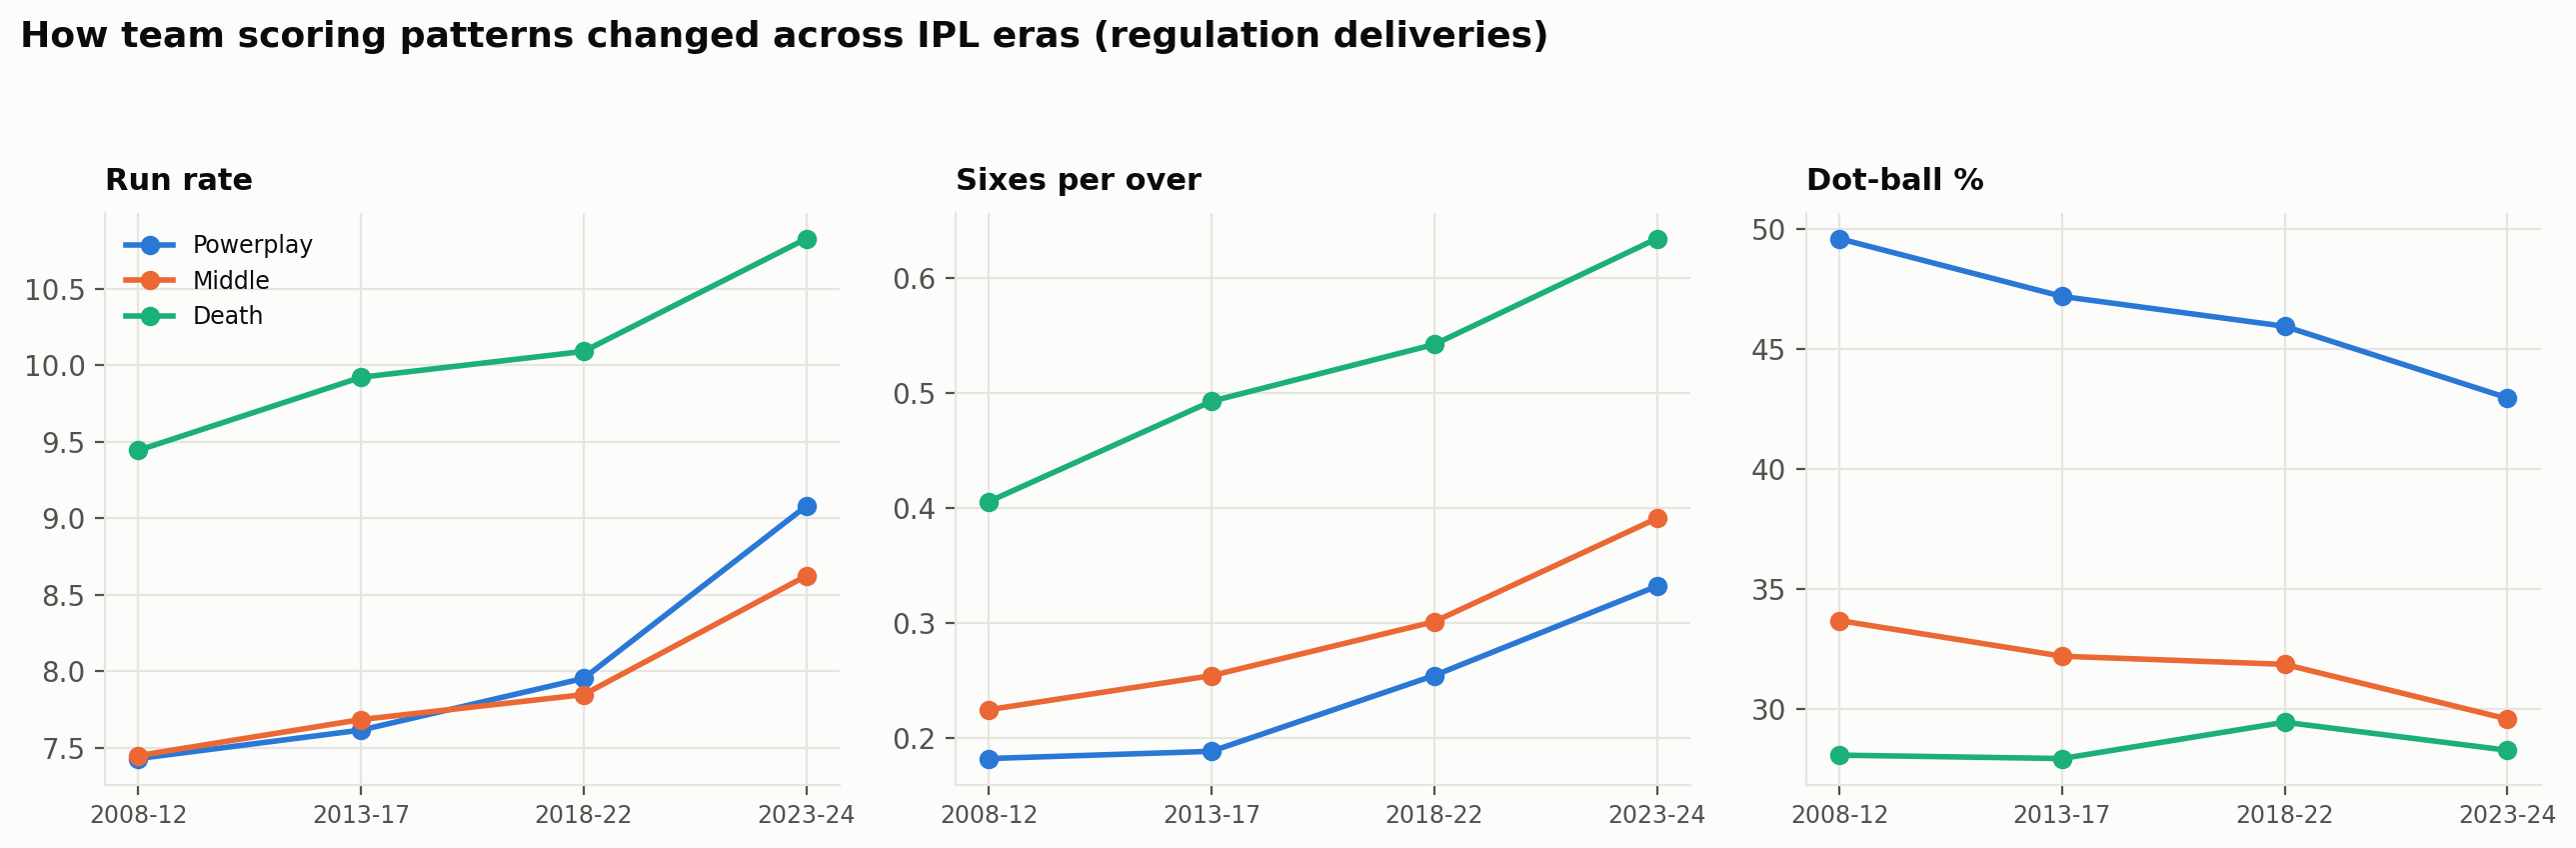

**6. Interpretation.** From 2008-12 to 2023-24 the Powerplay run rate rose from 7.43 to 9.08 and sixes per over from 0.18 to 0.33; death-overs sixes per over rose from 0.41 to 0.63. Dot-ball % fell in 2 of 3 phases (Powerplay 49.6% -> 43.0%). Balls per dismissal changed little (Powerplay 24.5 -> 23.7; death 11.7 -> 12.1): the extra runs came without wickets becoming rarer, consistent with more aggressive batting.

**7. Limitations.** Era boundaries are analyst-chosen; the 2023-24 era has two seasons only.

In [29]:
show('D6')

## E. Venue & conditions

### E1

**1. Question.** Which grounds are high- or low-scoring in each phase once season effects are removed?

**2. Metric.** Venue run rate in each phase minus the league rate expected for the same seasons and phase.

**3. Calculation.** `e1_venue_phase`

**4. Sample.** 15 venues with >= 20 full matches.

phase,venue,Powerplay,Middle,Death
0,Brabourne Stadium,0.92,0.39,0.32
1,M Chinnaswamy Stadium,0.02,0.54,0.89
2,Wankhede Stadium,-0.08,0.23,0.54
3,PCA IS Bindra (Mohali),0.40,0.31,-0.06
4,Arun Jaitley Stadium,0.45,0.15,-0.09
5,Eden Gardens,0.19,0.06,0.11
6,Narendra Modi Stadium,-0.20,0.07,-0.15
7,Sawai Mansingh Stadium,-0.26,-0.01,-0.29
8,Dubai Intl,-0.15,-0.25,-0.20
9,Rajiv Gandhi (Hyderabad),-0.06,-0.14,-0.40


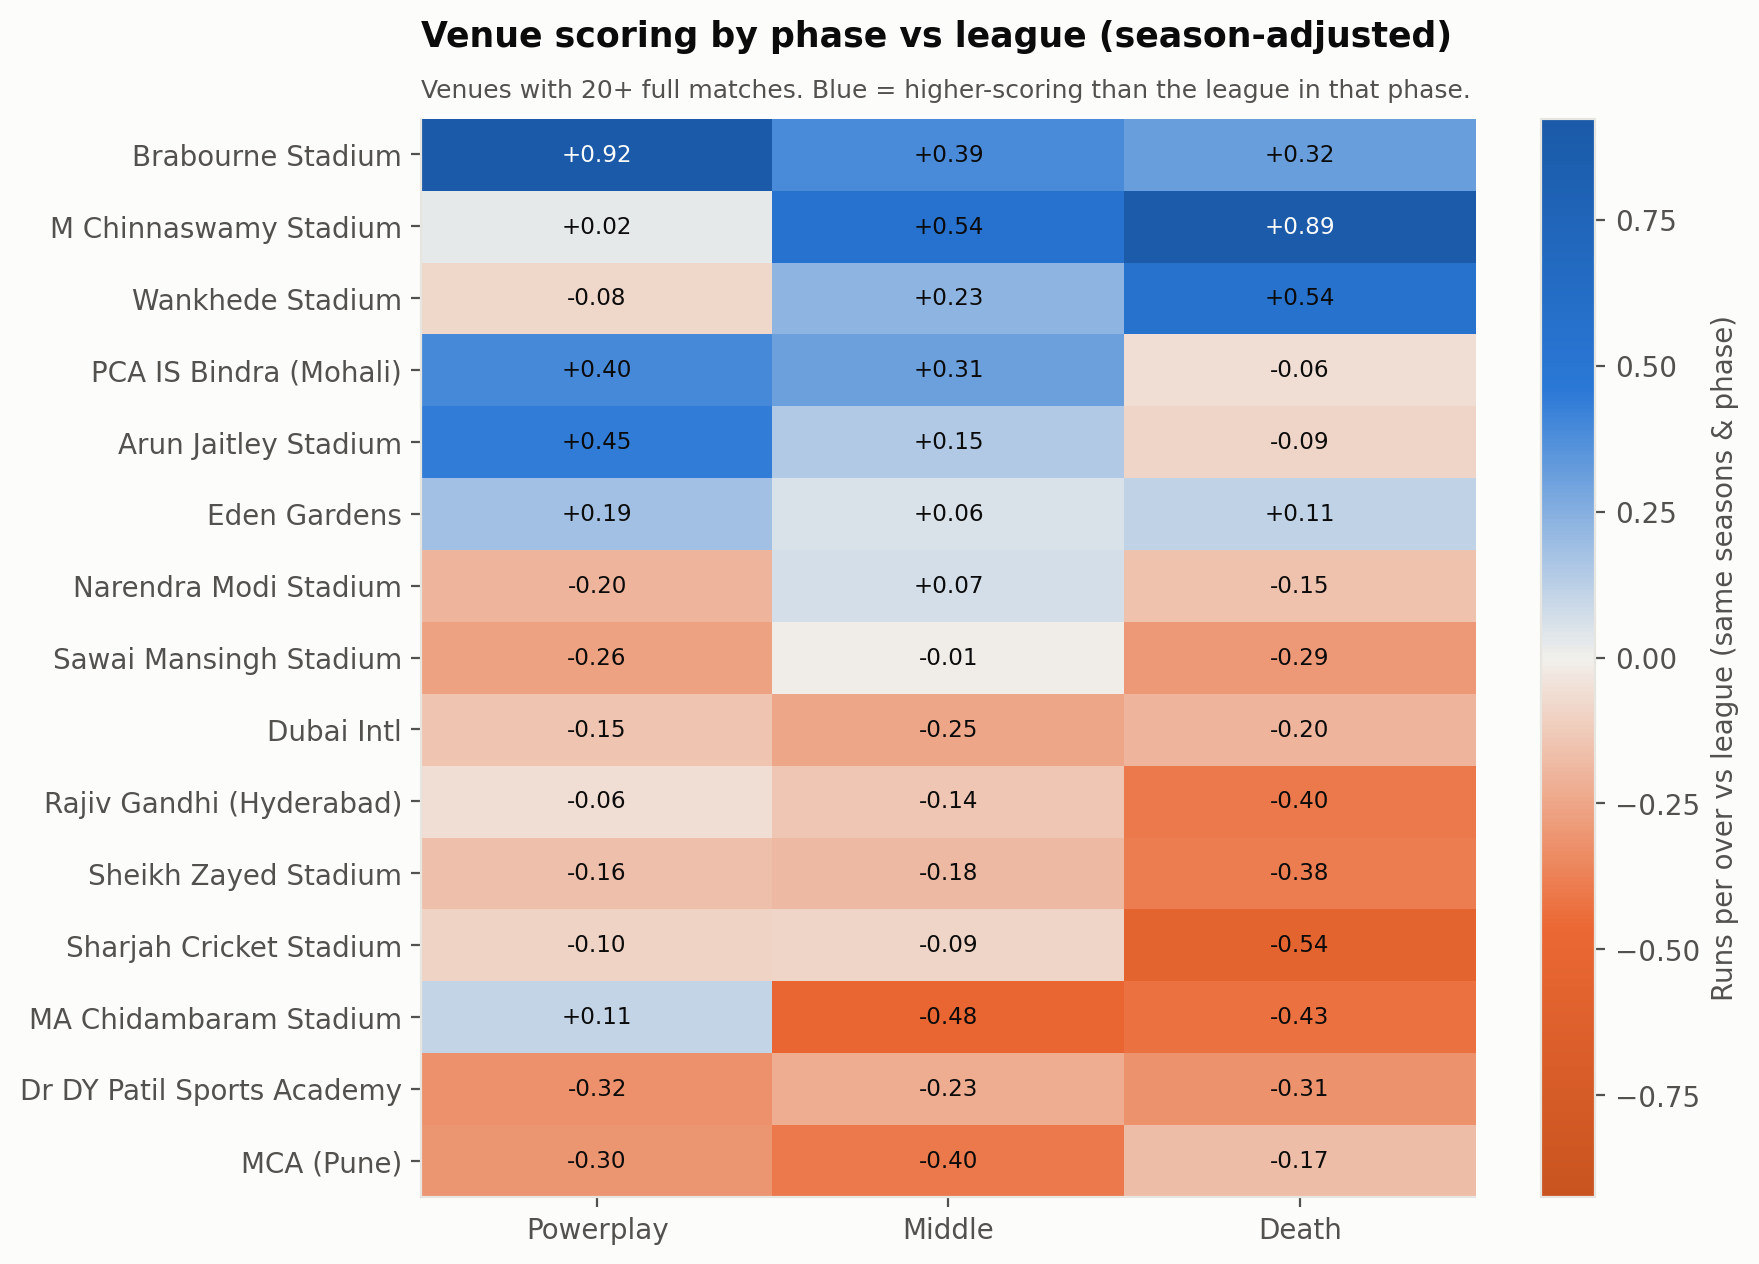

**6. Interpretation.** Brabourne Stadium is the highest-scoring venue relative to the league (Powerplay +0.92, Middle +0.39, Death +0.32 runs/over) and MCA (Pune) the lowest. Venues above the league in all three phases: Brabourne Stadium, M Chinnaswamy Stadium, Eden Gardens. 10 of 15 venues are on the same side of the league in all three phases, and Powerplay and death-over venue effects correlate at rho = 0.42: venue character is partly consistent across phases, but 5 venues switch between above and below the league depending on the phase.

**7. Limitations.** Venue effects are confounded with home teams' styles (no home-team field).

In [30]:
show('E1')

### E2

In [31]:
show('E2')

**1. Question.** Does the chance of winning while chasing really differ between venues, or are venue differences noise?

**2. Metric.** Venue x result_for contingency table (batting first / chasing); chi-square test of homogeneity; Wilson CIs.

**3. Calculation.** `e2_venue_chase_test`

**4. Sample.** 15 venues with >= 20 decided matches; 921 matches.

result_for,venue,decided,chasing,chase_win_pct,ci_low,ci_high
0,Sawai Mansingh Stadium,57,37,64.9,51.9,76.0
1,Sharjah Cricket Stadium,28,18,64.3,45.8,79.3
2,Sheikh Zayed Stadium,35,21,60.0,43.6,74.4
3,Eden Gardens,93,55,59.1,49.0,68.6
4,Narendra Modi Stadium,35,20,57.1,40.9,72.0
5,Punjab Cricket Association IS Bindra Stadium,61,34,55.7,43.3,67.5
6,Rajiv Gandhi International Stadium,76,42,55.3,44.1,65.9
7,Wankhede Stadium,117,64,54.7,45.7,63.4
8,M Chinnaswamy Stadium,90,49,54.4,44.2,64.3
9,Dr DY Patil Sports Academy,37,20,54.1,38.4,69.0


**6. Interpretation.** Chase win % ranges from 43.4% to 64.9% across venues, but the chi-square test gives chi2 = 11.9 (dof = 14), p = 0.61: the data does NOT provide significant evidence that venue changes the batting-first/chasing balance. The league-wide chasing edge (~54%) is the safer planning assumption than venue-specific rates.

**7. Limitations.** Minimum expected cell count 12.4 (>= 5 required) - assumption met.

### E3

In [32]:
show('E3')

**1. Question.** At high-scoring grounds, is the extra scoring driven by fewer wickets, fewer dot balls or more boundaries?

**2. Metric.** Per venue: bowler wickets vs expected (season & phase), dot %, boundary %; Spearman correlations with the venue's season-adjusted first-innings score.

**3. Calculation.** `e3_venue_bowling`

**4. Sample.** 15 venues with >= 20 full matches.

,venue,avg_inn1_vs_season,econ_vs_league,wkts_vs_expected,dot_pct,boundary_pct
5,M Chinnaswamy Stadium,9.77,0.44,1.02,35.63,18.95
1,Brabourne Stadium,9.68,0.51,1.02,34.64,19.36
0,Arun Jaitley Stadium,4.81,0.20,1.00,34.74,18.00
9,Punjab Cricket Association IS Bindra Stadium,4.25,0.23,0.98,33.11,17.40
14,Wankhede Stadium,2.98,0.20,1.01,36.77,18.52
4,Eden Gardens,1.37,0.09,0.98,36.72,18.40
3,Dubai International Cricket Stadium,-1.97,-0.19,1.02,35.67,15.56
7,Maharashtra Cricket Association Stadium,-2.89,-0.32,0.98,36.17,15.54
6,MA Chidambaram Stadium,-2.91,-0.28,0.98,35.75,15.47
10,Rajiv Gandhi International Stadium,-3.75,-0.15,0.97,35.74,16.63


**6. Interpretation.** Across venues, higher scoring goes with more boundaries (rho = 0.69, p = 0.004) and fewer dot balls (rho = -0.27, p = 0.328), while wicket-taking relative to expectation is only weakly related (rho = -0.05, p = 0.850). Of these, only the boundary relationship is statistically significant: high-scoring grounds are mainly 'boundary grounds' rather than 'no-wicket grounds'.

**7. Limitations.** 15 venues is a small sample for correlation; boundary size and pitch type are not in the data.

### E4

**1. Question.** What first-innings score gives the batting side an even chance, and has it changed?

**2. Metric.** Logistic regression of batting-first win (0/1) on first-innings runs, fitted separately for 2008-22 and 2023-24; par = score at 50% predicted win probability; 95% CI from 500 bootstrap resamples.

**3. Calculation.** `e4_first_innings_outcome`

**4. Sample.** 1047 full, non-D/L, decided matches (141 in 2023-24).

,period,matches,par_score_50pct,par_ci_low,par_ci_high,runs_for_+10pp_at_par,slope_per_run
0,2008-22,906.0,170.22,166.40,173.87,10.75,0.04
1,2023-24,141.0,183.35,171.02,195.81,12.90,0.03
2,difference (2023-24 minus 2008-22),NaN,13.13,0.79,25.70,NaN,NaN


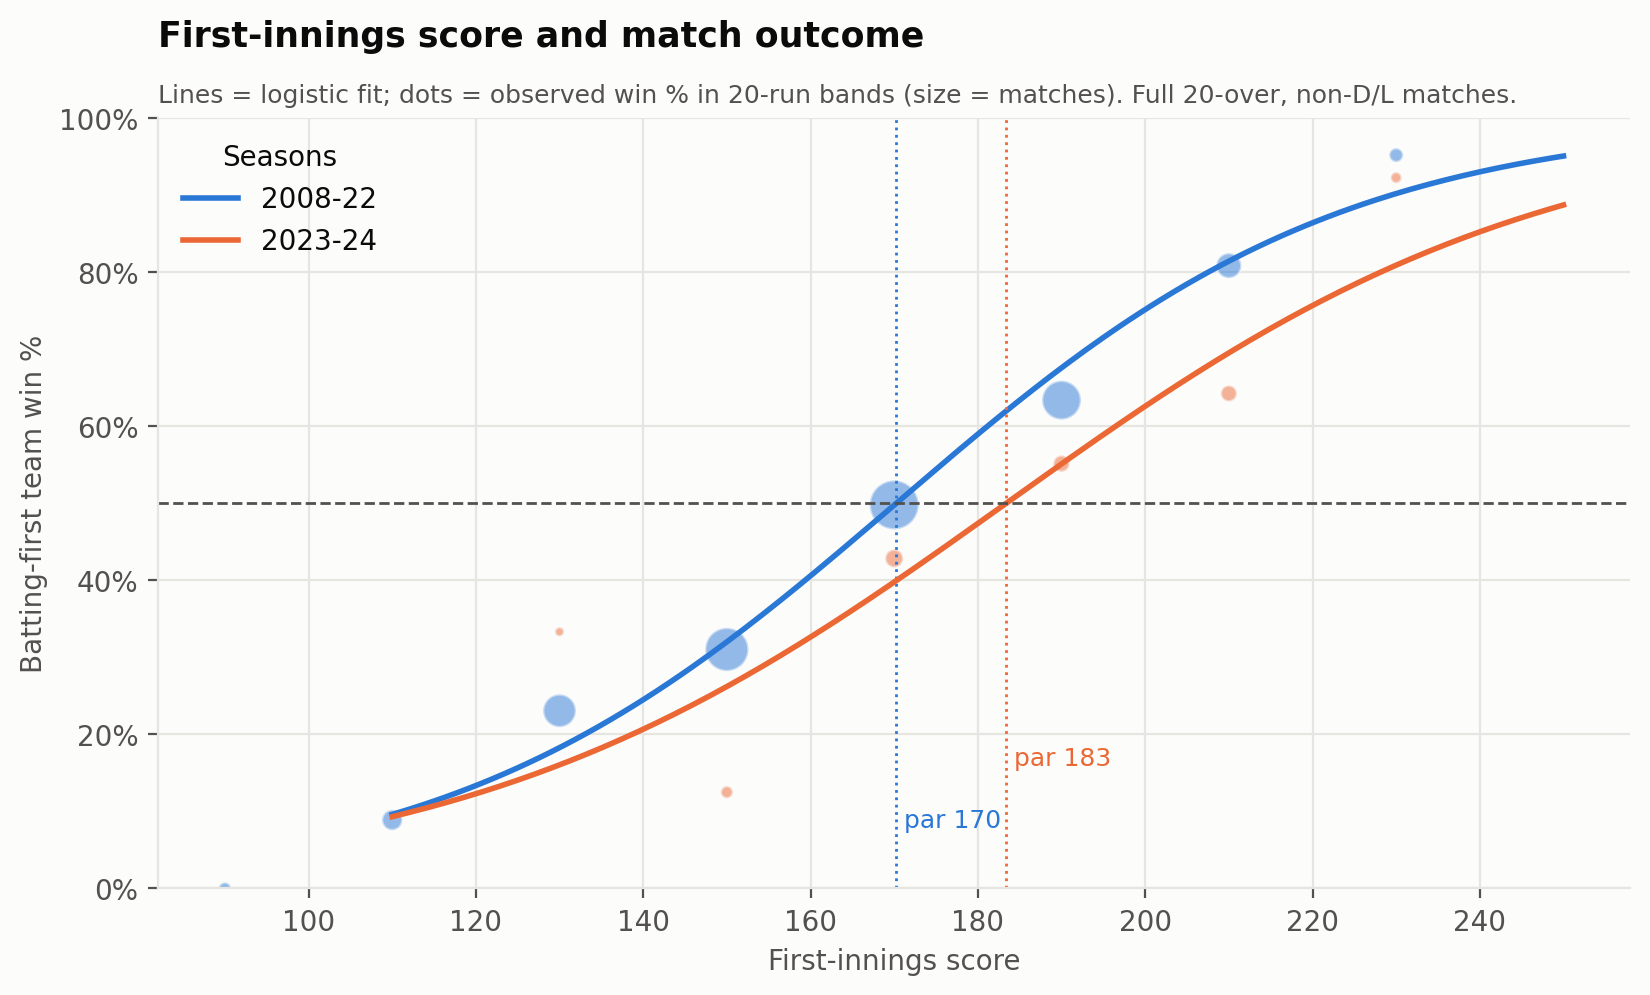

**6. Interpretation.** The par score was 170 in 2008-22 (95% CI 166-174) and 183 in 2023-24 (CI 171-196). Around par, each extra 10 runs adds about 9 percentage points of win probability (2008-22). The estimated rise in par is +13 runs (bootstrap 95% CI +1 to +26); the interval excludes zero, so the par score has risen beyond what sampling noise explains.

**7. Limitations.** Descriptive model (one predictor); venue and team strength not included.

In [33]:
show('E4')

## F. Machine-learning assessment

### F1

**1. Question.** Can a model add reliable, decision-useful prediction beyond the descriptive analysis?

**2. Metric.** Assessed two candidate tasks. (1) PRE-MATCH winner prediction: rejected - see finding. (2) IN-CHASE win probability from the match state (required rate, wickets in hand, balls left, runs needed), all derivable at the end of each over: tested with a time-based split (train 2008-21, test 2022-24, whole matches never split), against two baselines; metrics Brier score, log loss, ROC AUC and a calibration table.

**3. Calculation.** `f1_ml_assessment`

**4. Sample.** Train 14,950 over-end states from 832 chases; test 3,864 states from 215 chases.

,model,brier,log_loss,roc_auc
0,Base rate (always predict training win %),0.2536,0.7003,0.5000
1,Lookup table: over x required-rate x wickets bands,0.1545,0.5146,0.8594
2,Logistic regression (4 features),0.1439,0.4413,0.8800


**Calibration (test seasons)**

,bin,states,mean_predicted,observed
0,"(-0.001, 0.1]",900,0.036,0.047
1,"(0.1, 0.2]",488,0.148,0.234
2,"(0.2, 0.3]",354,0.247,0.322
3,"(0.3, 0.4]",269,0.351,0.420
4,"(0.4, 0.5]",293,0.451,0.454
5,"(0.5, 0.6]",295,0.548,0.681
6,"(0.6, 0.7]",245,0.651,0.759
7,"(0.7, 0.8]",295,0.748,0.793
8,"(0.8, 0.9]",288,0.851,0.899
9,"(0.9, 1.0]",437,0.956,0.966


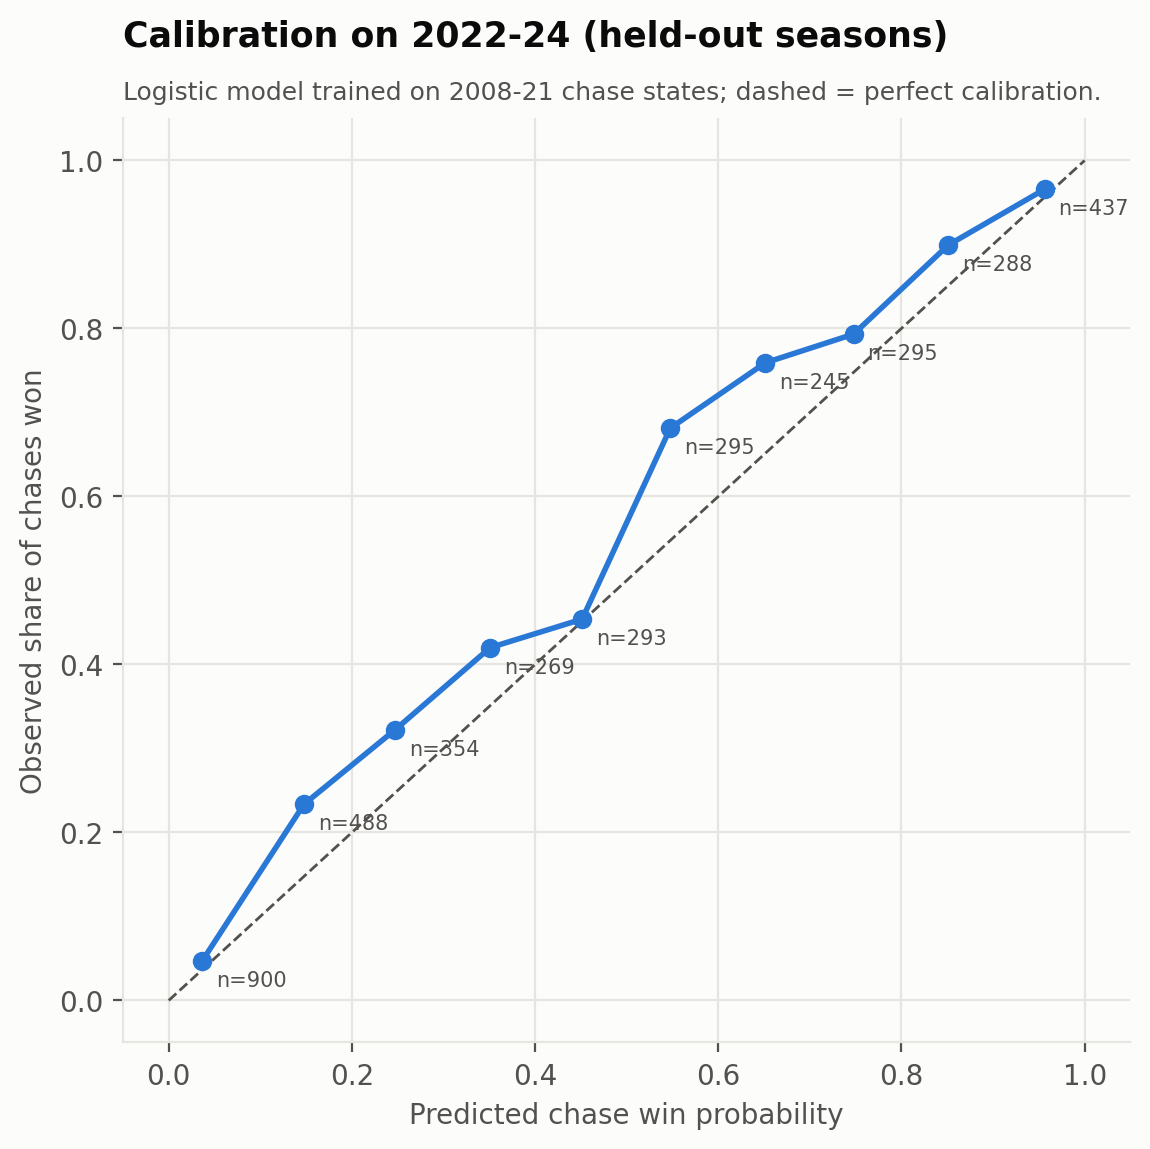

**6. Interpretation.** Pre-match prediction is not justified: the only pre-match signals in the data (toss 50.8%, chasing ~54%, venue - E2 not significant) are near coin-flip, squads change every season and there is no player availability data, so any model would be weak and misleading. The in-chase task IS supported: on unseen 2022-24 seasons the logistic model reaches AUC 0.880 and Brier 0.144 vs 0.254 for the base rate and 0.154 for the lookup table (best: Logistic regression (4 features)). Coefficients have the expected signs (required rate -0.43, wickets in hand +0.56). It is a transparent win-probability curve suitable for a dashboard visual - not a betting or selection tool.

**7. Limitations.** Leakage control: only information known at the end of the over; split by season so no match appears in both sets. Over-end states from the same chase are correlated, so metrics are optimistic about effective sample size. Era shift (2023-24 scoring) is the main risk; check calibration before reuse. No team/player strength, venue or D/L chases included.

In [34]:
show('F1')

## Outputs
- `reports/advanced_analytics_report.md`
- `reports/advanced_analytics_validation_report.md`
- `reports/advanced_analytics_summary.csv`
- `reports/advanced_analytics_tables/`
- `reports/charts/phase5/`